# AI Usage & Its Impact on Students and Professionals
### End-to-end data science project: cleaning → EDA → feature engineering → modelling → evaluation → recommendations

**Dataset:** `AI_Usage_and_Impact_on_Students_and_Professionals.csv` (300 survey rows, 19 columns)

**Notebook map**

| # | Section |
|---|---------|
| 1 | Problem statement |
| 2 | Proposed solution |
| 3 | Setup |
| 4 | Data loading & raw audit |
| 5 | Deep data cleaning |
| 6 | Missing values & outliers |
| 7 | Exploratory data analysis & visualisation |
| 8 | Feature engineering (with the maths) |
| 9 | Train / test split & leakage-safe preprocessing |
| 10 | Scaling / normalisation |
| 11 | Feature reduction |
| 12 | Model comparison (regression) |
| 13 | Hyper-parameter tuning & nested CV |
| 14 | Final test evaluation |
| 15 | Under-fitting / over-fitting diagnosis |
| 16 | Data-leakage audit |
| 17 | Interpretation |
| 18 | Secondary task: will the user recommend AI? (classification) |
| 19 | Recommendations & solution summary |

> **To run locally:** put the CSV next to this notebook (or edit `DATA_PATH` below) and run all cells.
> Requirements: `pandas numpy scipy scikit-learn matplotlib seaborn`.

## 1. Problem Statement

Generative-AI tools (ChatGPT, Claude, Gemini, Copilot, …) are now part of everyday study and work, yet **how much real benefit people get differs enormously**. Some users report large productivity gains, while others spend time and money on AI and gain little.

Educators, employers and tool vendors need evidence-based answers to:

1. **What drives self-reported productivity gain from AI?** Is it *how much* people use AI, *which tool*, *what for*, *who they are* (student vs professional, education, income), or *how well* the AI performs for them?
2. **Can we predict a user's `Productivity_Score`** from their profile and usage pattern, so that low-benefit users can be identified and supported early?
3. **Which users will recommend AI to others** (`Would_Recommend`)? This is a proxy for sustained adoption.

**Difficulties in this dataset (and why a careful pipeline is needed)**

* Only **300 rows**, so models can easily over-fit; honest validation is critical.
* **Very messy data**: units embedded in strings (`"2 hrs"`, `"$20"`, `"30 yrs"`), inconsistent labels (`ChatGPT / Chat GPT / chatgpt`, `U.K. / United Kingdom`), multilingual job titles, duplicate IDs, impossible values (age 97, 23 AI-hours/day) and missing values in every column.
* **Leakage traps**: several columns (satisfaction, time saved, perceived accuracy) are *outcomes measured at the same time as the target*, so including them can silently inflate performance.

**Targets**

| Task | Target | Type |
|------|--------|------|
| Primary | `Productivity_Score` (1–10) | Regression |
| Secondary | `Would_Recommend == "Yes"` | Binary classification |

## 2. Proposed Solution

A reproducible, leakage-safe pipeline:

1. **Audit & clean** – parse units, harmonise categories, fix/flag impossible values, remove duplicate respondents, log every change.
2. **Understand** – univariate, bivariate and multivariate EDA plus formal statistical tests (Mann-Whitney, Kruskal-Wallis, Spearman).
3. **Engineer features with explicit mathematics** – log / power transforms for skew, ratios (AI-share of working time, cost-to-income), polynomial terms for diminishing returns, text statistics and TF-IDF → truncated-SVD latent topics from the free-text task descriptions.
4. **Split first, fit later** – the train/test split happens *before* any statistic is learned. Imputers, scalers, encoders, TF-IDF, PCA and selectors live **inside scikit-learn `Pipeline`s** so they are re-fitted on each training fold only.
5. **Reduce dimensionality** – variance filter, correlation analysis, VIF, PCA (verified against a manual eigen-decomposition) and L1 selection.
6. **Model** – baseline, linear (OLS/Ridge/Lasso/ElasticNet), KNN, SVR and tree ensembles; repeated K-fold CV; tuning with randomised/grid search; nested CV for an unbiased estimate of the tuned model.
7. **Validate honestly** – train-vs-CV gaps, learning & validation curves, target-shuffle (permutation) test, train/test overlap check, a with/without-outcome-features experiment to quantify leakage, bootstrap CIs on the untouched test set.
8. **Recommend** – translate findings into actions.

## 3. Setup

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, RepeatedKFold, RepeatedStratifiedKFold, KFold,
                                     StratifiedKFold, cross_validate, cross_val_score, GridSearchCV,
                                     RandomizedSearchCV, learning_curve, validation_curve,
                                     permutation_test_score)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, RobustScaler, PowerTransformer, OneHotEncoder)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression, lasso_path
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestClassifier,
                              GradientBoostingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve,
                             balanced_accuracy_score, ConfusionMatrixDisplay)
from sklearn.base import clone
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50, "display.width", 160, "display.float_format", "{:.3f}".format)

DATA_PATH = "AI_Usage_and_Impact_on_Students_and_Professionals.csv"

print("Using:", DATA_PATH)

Using: AI_Usage_and_Impact_on_Students_and_Professionals.csv


## 4. Data Loading & Raw Audit

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=True)   # read everything as text: units hide inside the cells

for c in ["Productivity_Score", "Accuracy_Rating", "Satisfaction_Score"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
    
print("Shape:", raw.shape)

display(raw.head(5))

Shape: (300, 19)


,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.300,4.000,7.000,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.900,3.000,9.000,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.200,2.000,4.000,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.600,4.000,5.000,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.700,4.000,7.000,9.2,6.2,Yes


In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_missing": raw.isna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
})
display(audit)
print("Exact duplicate rows:", raw.duplicated().sum(), "| Duplicate User_IDs:", raw["User_ID"].duplicated().sum())

,dtype,n_missing,pct_missing,n_unique
User_ID,object,0,0.000,288
Age,object,23,7.700,52
Gender,object,10,3.300,11
Country,object,10,3.300,20
User_Type,object,0,0.000,2
Education_Level,object,13,4.300,16
Profession,object,15,5.000,126
Monthly_Income,object,10,3.300,233
AI_Tool,object,11,3.700,16
AI_Purpose,object,13,4.300,8


Exact duplicate rows: 12 | Duplicate User_IDs: 12


**Raw-audit findings** (what the cleaning step must fix)

* Numeric columns stored as text with units: `"2 hrs"`, `"$20 "`, `"30 yrs"`.
* Category spelling variants: Gender (`F`, `FEMALE`, `female`…), Country (`U.K.`, `United States of America`, `canada`), Education (`BA/BSc`, `Bachelors`, `bachelor's degree`…), AI tool (`Chat GPT`, `chatgpt`, `Google Gemini`…).
* Profession has 126 free-text values, including non-English titles.
* Duplicate respondents (same `User_ID`, formatted differently).
* Suspicious values (age 97, 23 AI hours/day) – to be validated against plausibility rules.

## 5. Deep Data Cleaning

Every rule is explicit and every change is counted in a **cleaning log**, so the process is auditable.
All cleaning rules here are **row-wise** (no statistics learned from the data), so doing them before the train/test split cannot leak information.

In [4]:
log = []                       # (step, rows/cells affected)
def note(step, n): log.append({"step": step, "affected": int(n)})

df = raw.copy()

# 5.1 whitespace / empty strings -> NaN ---------------------------------------------------
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()
    df[c] = df[c].mask(df[c] == "", pd.NA)

# 5.2 numeric parsing: strip units/symbols ("2 hrs", "$20", "30 yrs") ----------------------
def to_num(s):
    cleaned = s.astype("string").str.replace(",", "", regex=False)
    return pd.to_numeric(cleaned.str.extract(r"(-?\d+(?:\.\d+)?)")[0], errors="coerce").astype("float64")

num_text_cols = ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost",
                 "Time_Saved_Hours_Per_Week", "Work_or_Study_Hours_Per_Day"]
for c in num_text_cols:
    had_unit = df[c].str.contains(r"[A-Za-z$]", na=False).sum()
    df[c] = to_num(df[c])
    note(f"Parsed '{c}' to float (units stripped)", had_unit)

# 5.3 category harmonisation ---------------------------------------------------------------
def map_gender(x):
    if pd.isna(x): return np.nan
    t = x.lower()
    return "Female" if t in ("f", "female") else "Male" if t in ("m", "male") else "Other"

def map_country(x):
    if pd.isna(x): return np.nan
    t = re.sub(r"[^a-z ]", "", x.lower()).strip()
    if t in ("uk", "united kingdom"): return "United Kingdom"
    if t in ("us", "usa", "united states", "united states of america"): return "United States"
    return t.title()

def map_edu(x):
    if pd.isna(x): return np.nan
    t = x.lower()
    if "high school" in t or t == "hs": return "High School"
    if "diploma" in t: return "Diploma"
    if "undergrad" in t: return "Undergraduate"
    if "ba/bsc" in t or "bachelor" in t: return "Bachelor's"
    if "ma/msc" in t or "master" in t: return "Master's"
    if "ph" in t: return "PhD"
    return x

def map_tool(x):
    if pd.isna(x): return np.nan
    t = x.lower().replace(" ", "")
    for key, name in [("chatgpt", "ChatGPT"), ("gemini", "Gemini"), ("copilot", "Copilot"), ("claude", "Claude"),
                      ("deepseek", "DeepSeek"), ("grammarly", "Grammarly"), ("metaai", "Meta AI"),
                      ("perplexity", "Perplexity")]:
        if key in t: return name
    return x

# Profession -> role family (ordered keyword rules; handles a few non-English titles)
FAMILY_RULES = [
    ("Customer Support", r"customer|support|soporte|atenci"),
    ("Tech / Data",      r"software|develop|desenvolv|d[eé]veloppeur|programm|computer science|information technology|data|full stack|devops|\bit\b"),
    ("Writing / Media",  r"writ|content|market|media|literature|creative|journal|communicat|english|history|copy"),
    ("Business / Admin", r"business|admin|analyst|manager|financ|account"),
    ("Science / Research", r"research|biolog|biotech|physic|chemist|environment|molecular|science|medic|health"),
    ("Engineering",      r"engineer"),
]
def prof_family(x):
    if pd.isna(x): return "Unknown"
    t = x.lower()
    for fam, pat in FAMILY_RULES:
        if re.search(pat, t): return fam
    return "Other"

for col, fn in [("Gender", map_gender), ("Country", map_country), ("Education_Level", map_edu), ("AI_Tool", map_tool)]:
    before = df[col].copy()
    df[col] = df[col].map(fn)
    note(f"Harmonised '{col}' labels", (before.notna() & (before != df[col])).sum())
df["Profession_Family"] = df["Profession"].map(prof_family)
note("Mapped 'Profession' (free text) -> Profession_Family", df["Profession"].notna().sum())

# 5.4 plausibility rules: impossible values -> NaN (imputed later, inside the pipeline) ------
rules = {
    # Monthly_Income upper bound 50,000: one 17-yr-old student reports 250,000/month (next-highest is 10,311) -> data-entry error
    "Age": (14, 80), "Monthly_Income": (0, 50000), "AI_Usage_Hours_Per_Day": (0, 16),
    "Work_or_Study_Hours_Per_Day": (0, 16), "Time_Saved_Hours_Per_Week": (0, 60), "Monthly_AI_Cost": (0, None),
    "Productivity_Score": (0, 10), "Accuracy_Rating": (1, 5), "Satisfaction_Score": (1, 10),
}
for c, (lo, hi) in rules.items():
    bad = pd.Series(False, index=df.index)
    if lo is not None: bad |= df[c] < lo
    if hi is not None: bad |= df[c] > hi
    if bad.any():
        print(f"{c}: invalid values set to NaN ->", df.loc[bad, c].tolist())
    df.loc[bad, c] = np.nan
    note(f"Implausible '{c}' -> NaN", bad.sum())

# logical consistency flag (kept, not removed: a student can use AI outside study time)
df["ai_exceeds_work_hours"] = (df["AI_Usage_Hours_Per_Day"] > df["Work_or_Study_Hours_Per_Day"]).astype(float)
note("Flag: AI hours > work/study hours (kept as feature)", df["ai_exceeds_work_hours"].sum())

# 5.5 de-duplicate respondents ---------------------------------------------------------------
n0 = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "User_ID"] + ["User_ID"])
note("Exact duplicate rows removed (after harmonising formats)", n0 - len(df))
n1 = len(df)
df["_nmiss"] = df.isna().sum(axis=1)
df = df.sort_values(["User_ID", "_nmiss"]).drop_duplicates("User_ID", keep="first").drop(columns="_nmiss")
note("Remaining duplicate User_IDs resolved (kept the most complete record)", n1 - len(df))

# 5.6 target must not be imputed: drop rows without it ---------------------------------------
n2 = len(df)
df = df.dropna(subset=["Productivity_Score"]).reset_index(drop=True)
note("Rows dropped: missing target (Productivity_Score)", n2 - len(df))

display(pd.DataFrame(log))
print("Clean shape:", df.shape)

Age: invalid values set to NaN -> [97.0, 97.0]
Monthly_Income: invalid values set to NaN -> [250000.0]
AI_Usage_Hours_Per_Day: invalid values set to NaN -> [23.0]
Work_or_Study_Hours_Per_Day: invalid values set to NaN -> [20.0, 20.0]


,step,affected
0,Parsed 'Age' to float (units stripped),14
1,Parsed 'Monthly_Income' to float (units stripped),6
2,Parsed 'AI_Usage_Hours_Per_Day' to float (unit...,22
3,Parsed 'Monthly_AI_Cost' to float (units strip...,15
4,Parsed 'Time_Saved_Hours_Per_Week' to float (u...,18
5,Parsed 'Work_or_Study_Hours_Per_Day' to float ...,12
6,Harmonised 'Gender' labels,51
7,Harmonised 'Country' labels,14
8,Harmonised 'Education_Level' labels,17
9,Harmonised 'AI_Tool' labels,110


Clean shape: (274, 21)


In [5]:
# sanity check: the harmonised categorical columns should now be tidy
for c in ["Gender", "Country", "Education_Level", "AI_Tool", "AI_Purpose", "Profession_Family", "User_Type", "Would_Recommend"]:
    print(f"{c:18s}", df[c].value_counts(dropna=False).to_dict())

Gender             {'Male': 138, 'Female': 112, 'Other': 15, nan: 9}
Country            {'India': 41, 'United States': 33, 'Canada': 30, 'Brazil': 25, 'Pakistan': 25, 'United Kingdom': 24, 'Philippines': 23, 'Australia': 20, 'Nigeria': 16, 'Germany': 12, nan: 10, 'France': 10, 'Kenya': 5}
Education_Level    {"Bachelor's": 71, 'Undergraduate': 61, "Master's": 47, 'High School': 45, 'Diploma': 25, 'PhD': 14, nan: 11}
AI_Tool            {'ChatGPT': 113, 'Gemini': 38, 'Copilot': 31, 'Claude': 29, 'Perplexity': 20, 'Grammarly': 14, 'Meta AI': 10, nan: 10, 'DeepSeek': 9}
AI_Purpose         {'Coding': 63, 'Writing': 47, 'Studying': 38, 'Research': 35, 'Content Creation': 26, 'Data Analysis': 22, 'Customer Support': 20, <NA>: 12, 'Office Work': 11}
Profession_Family  {'Tech / Data': 84, 'Writing / Media': 74, 'Science / Research': 36, 'Business / Admin': 22, 'Customer Support': 18, 'Other': 15, 'Engineering': 13, 'Unknown': 12}
User_Type          {'Student': 143, 'Professional': 131}
Would_Rec

## 6. Missing Values & Outliers

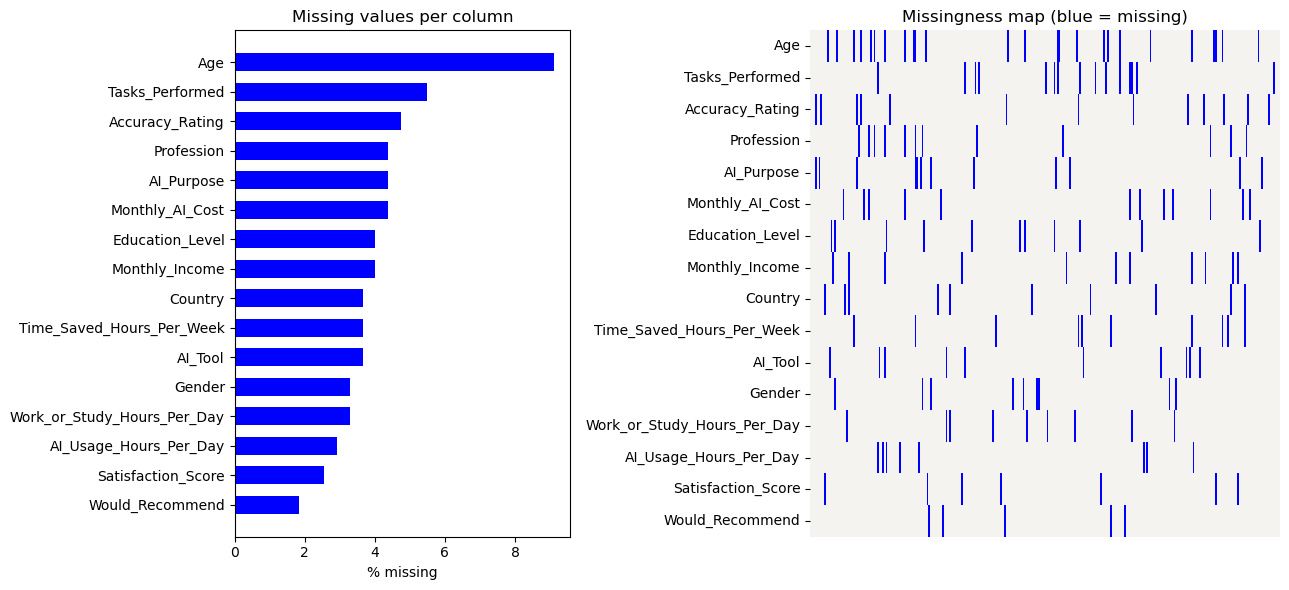

In [6]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].barh(miss.index[::-1], miss.values[::-1], color = "#0000FF", height=0.6)
ax[0].set_xlabel("% missing"); ax[0].set_title("Missing values per column")
sns.heatmap(df[miss.index].isna().T, cbar=False, cmap=["#f4f3ef", "#0000FF"], ax=ax[1], yticklabels=True, xticklabels=False)
ax[1].set_title("Missingness map (blue = missing)"); ax[1].grid(False)
plt.tight_layout(); plt.show()

In [7]:
# Is missingness related to the target? (MCAR vs MAR sanity check, Mann-Whitney U)
rows = []
for c in miss.index:
    if c == "Productivity_Score": continue
    a = df.loc[df[c].isna(), "Productivity_Score"]; b = df.loc[df[c].notna(), "Productivity_Score"]
    if len(a) > 2:
        p = stats.mannwhitneyu(a, b).pvalue
        rows.append((c, len(a), a.mean(), b.mean(), p))
mt = pd.DataFrame(rows, columns=["column", "n_missing", "mean_prod_if_missing", "mean_prod_if_present", "p_value"])
display(mt.sort_values("p_value"))
print("Columns with p<0.05:", (mt.p_value < 0.05).sum(), "of", len(mt),
      "-> missingness looks (close to) random, so median/mode imputation + missing-indicators is reasonable.")

,column,n_missing,mean_prod_if_missing,mean_prod_if_present,p_value
10,AI_Tool,10,6.080,5.203,0.108
8,Country,10,4.560,5.261,0.218
7,Monthly_Income,11,5.864,5.209,0.246
14,Satisfaction_Score,7,4.586,5.252,0.308
4,AI_Purpose,12,4.625,5.263,0.308
1,Tasks_Performed,15,5.860,5.199,0.336
9,Time_Saved_Hours_Per_Week,10,5.790,5.214,0.336
0,Age,25,5.552,5.203,0.340
3,Profession,12,4.908,5.250,0.579
11,Gender,9,4.989,5.243,0.638


Columns with p<0.05: 0 of 16 -> missingness looks (close to) random, so median/mode imputation + missing-indicators is reasonable.


**Imputation strategy** (statistics are learned **inside the pipeline on training folds only**):

* numeric → median (robust to skew) **+ a binary "was missing" indicator** (lets the model use informative missingness);
* categorical → explicit `"Unknown"` category (a constant, so safe to apply now);
* free text → empty string.

**Outliers** – with n≈290 we avoid deleting rows. We *detect* them with two complementary rules, then *treat* them with transforms (log / Yeo-Johnson) and robust models rather than removal.

$$\text{IQR rule: } x < Q_1 - 1.5\,\text{IQR} \ \text{ or } \ x > Q_3 + 1.5\,\text{IQR}$$

$$\text{Mahalanobis: } D_M^2(\mathbf x)=(\mathbf x-\boldsymbol\mu)^\top \Sigma^{-1}(\mathbf x-\boldsymbol\mu)\ \sim\ \chi^2_k \ \Rightarrow\ \text{flag if } D_M^2>\chi^2_{k,0.999}$$

Mahalanobis distance accounts for correlation between variables, so it finds *multivariate* outliers that the univariate IQR rule misses.

In [8]:
num_cols = ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost", "Time_Saved_Hours_Per_Week",
            "Work_or_Study_Hours_Per_Day", "Productivity_Score", "Accuracy_Rating", "Satisfaction_Score"]

# --- univariate IQR ---
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
iqr_out = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()

# --- multivariate Mahalanobis (complete cases) ---
cc = df[num_cols].dropna()
X = cc.values
mu = X.mean(0); S = np.cov(X, rowvar=False); S_inv = np.linalg.pinv(S)
d2 = np.einsum("ij,jk,ik->i", X - mu, S_inv, X - mu)
cut = stats.chi2.ppf(0.999, df=X.shape[1])
maha_flag = d2 > cut
print(pd.DataFrame({"IQR outliers": iqr_out, "% of rows": (iqr_out / len(df) * 100).round(1)}))
print(f"\nMahalanobis: {maha_flag.sum()} multivariate outliers out of {len(cc)} complete rows (chi2 cut = {cut:.1f})")
display(cc[maha_flag].head(10))

                             IQR outliers  % of rows
Age                                    12      4.400
Monthly_Income                         35     12.800
AI_Usage_Hours_Per_Day                  9      3.300
Monthly_AI_Cost                         2      0.700
Time_Saved_Hours_Per_Week              10      3.600
Work_or_Study_Hours_Per_Day             4      1.500
Productivity_Score                      0      0.000
Accuracy_Rating                         0      0.000
Satisfaction_Score                      0      0.000

Mahalanobis: 1 multivariate outliers out of 192 complete rows (chi2 cut = 27.9)


,Age,Monthly_Income,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Productivity_Score,Accuracy_Rating,Satisfaction_Score
91,32.000,524.000,7.200,100.000,11.700,6.500,9.400,3.000,8.000


## 7. Exploratory Data Analysis & Visualisation

### 7.1 Summary statistics, skewness and normality

In [9]:
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc["shapiro_p"] = [stats.shapiro(df[c].dropna()).pvalue for c in num_cols]
display(desc)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,shapiro_p
Age,249.000,29.598,11.166,16.000,22.000,26.000,35.000,64.000,1.227,1.047,0.000
Monthly_Income,263.000,1478.414,2130.753,0.000,109.500,524.000,1622.500,10311.000,1.905,3.066,0.000
AI_Usage_Hours_Per_Day,266.000,2.881,2.175,0.500,1.300,2.000,4.075,9.900,1.294,1.215,0.000
Monthly_AI_Cost,262.000,10.000,14.095,0.000,0.000,0.000,20.000,100.000,2.535,11.729,0.000
Time_Saved_Hours_Per_Week,264.000,5.857,4.154,0.000,2.800,4.950,7.750,19.400,0.895,0.262,0.000
Work_or_Study_Hours_Per_Day,265.000,7.224,1.845,2.100,6.000,7.200,8.400,12.400,0.173,0.219,0.248
Productivity_Score,274.000,5.235,1.822,1.600,3.900,5.000,6.500,10.000,0.391,-0.389,0.001
Accuracy_Rating,261.000,3.437,0.855,2.000,3.000,4.000,4.000,5.000,-0.155,-0.678,0.000
Satisfaction_Score,267.000,6.150,1.541,3.000,5.000,6.000,7.000,10.000,0.218,-0.324,0.000


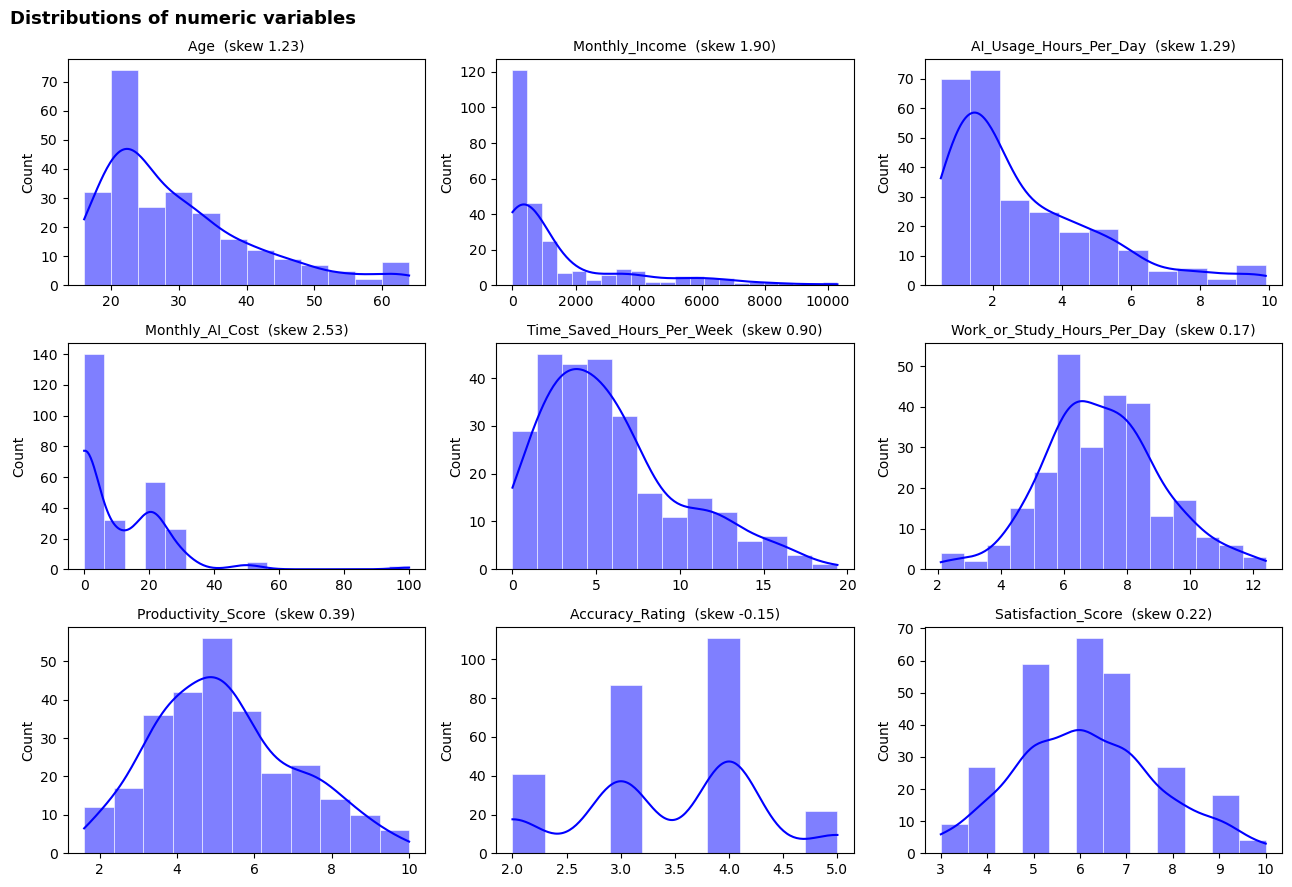

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c].dropna(), kde=True, color="#0000FF", ax=ax, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{c}  (skew {df[c].skew():.2f})", fontsize=10); ax.set_xlabel("")
plt.suptitle("Distributions of numeric variables", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the distributions:** income and AI cost are strongly right-skewed (many zeros for students, a few high earners) → log transform is justified. Scores are roughly bell-shaped.

### 7.2 Categorical composition

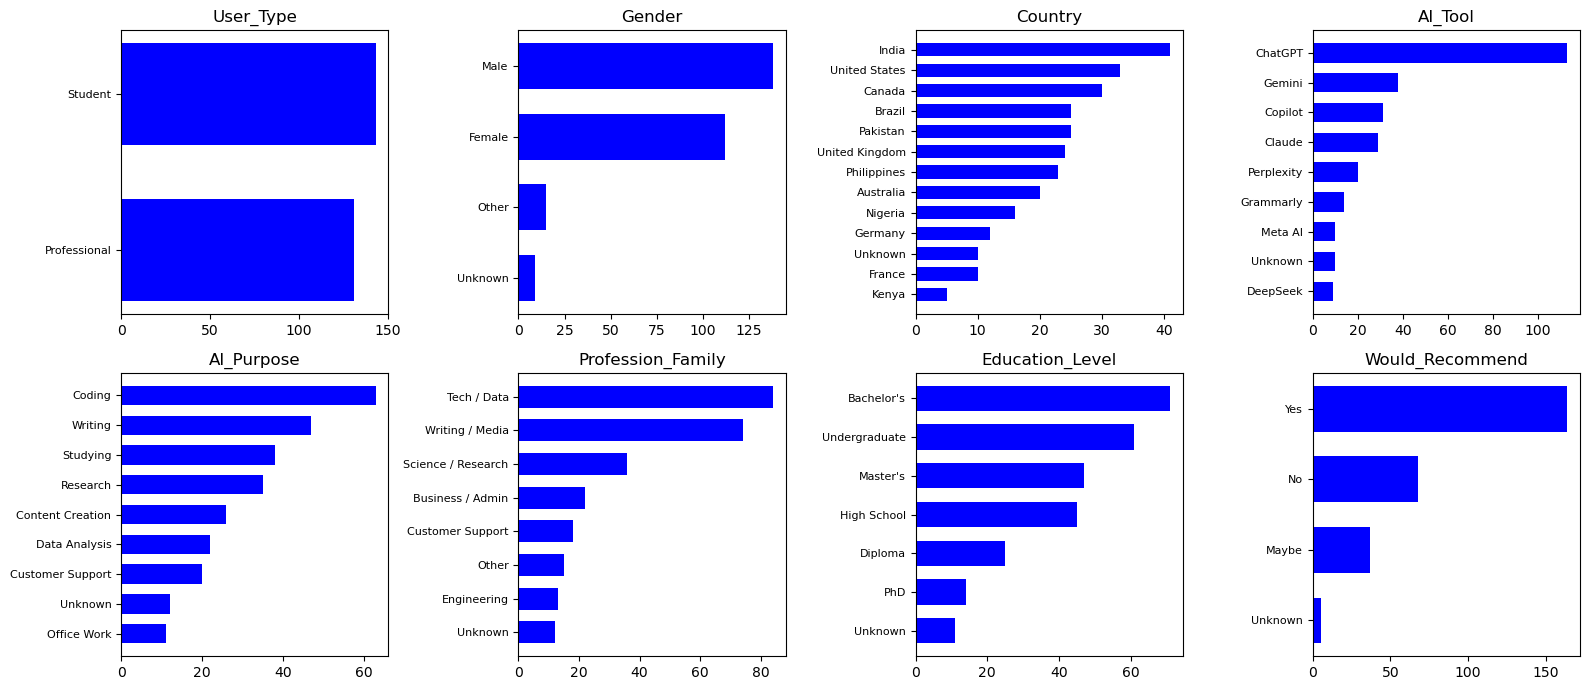

In [11]:
cats = ["User_Type", "Gender", "Country", "AI_Tool", "AI_Purpose", "Profession_Family", "Education_Level", "Would_Recommend"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), cats):
    vc = df[c].fillna("Unknown").value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color="#0000FF", height=0.65)
    ax.set_title(c); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

### 7.3 Target vs categories

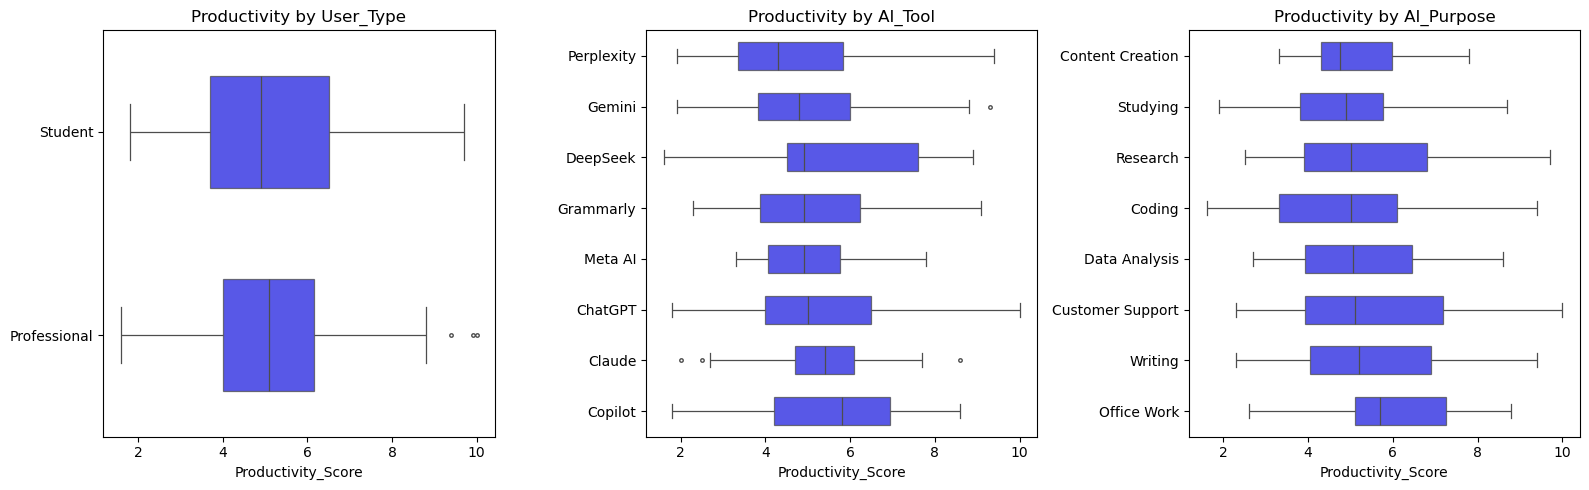

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, c in zip(axes, ["User_Type", "AI_Tool", "AI_Purpose"]):
    order = df.groupby(c)["Productivity_Score"].median().sort_values().index
    sns.boxplot(data=df, y=c, x="Productivity_Score", order=order, ax=ax, color="#0000FF", width=0.55,
                fliersize=2.5, linewidth=0.9, boxprops=dict(alpha=0.75))
    ax.set_title(f"Productivity by {c}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

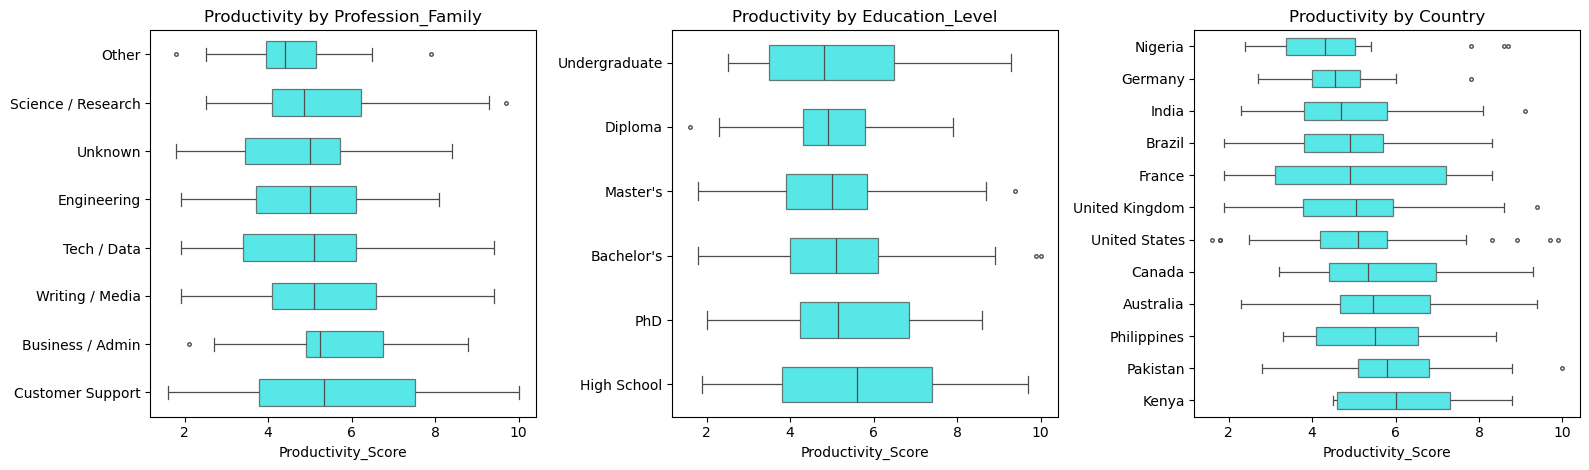

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, c in zip(axes, ["Profession_Family", "Education_Level", "Country"]):
    order = df.groupby(c)["Productivity_Score"].median().sort_values().index
    sns.boxplot(data=df, y=c, x="Productivity_Score", order=order, ax=ax, color= "#00FFFF", width=0.55,
                fliersize=2.5, linewidth=0.9, boxprops=dict(alpha=0.75))
    ax.set_title(f"Productivity by {c}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 7.4 Numeric relationships with the target

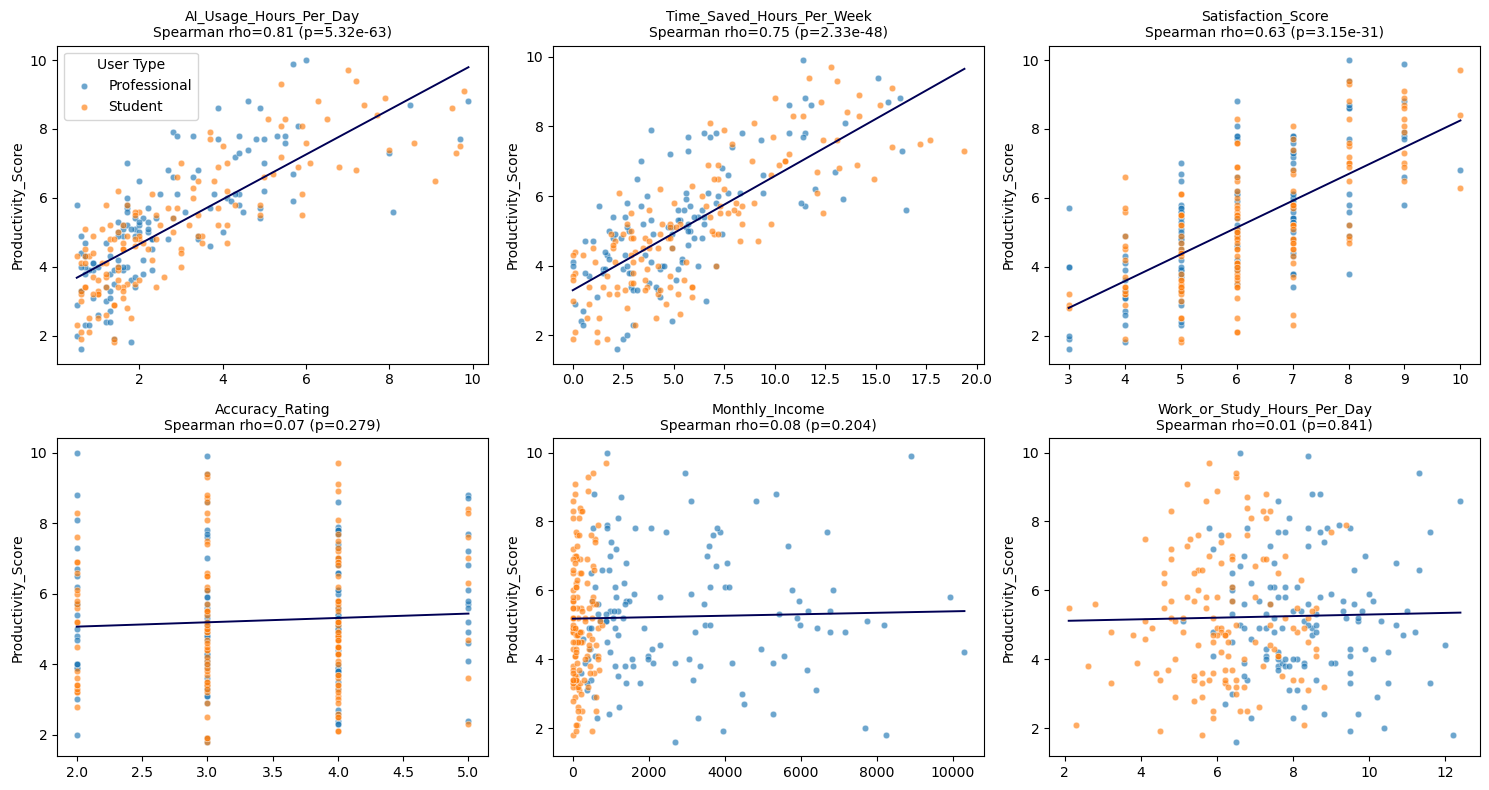

In [14]:

pairs = [
    ("AI_Usage_Hours_Per_Day", "Productivity_Score"),
    ("Time_Saved_Hours_Per_Week", "Productivity_Score"),
    ("Satisfaction_Score", "Productivity_Score"),
    ("Accuracy_Rating", "Productivity_Score"),
    ("Monthly_Income", "Productivity_Score"),
    ("Work_or_Study_Hours_Per_Day", "Productivity_Score")
]

# Assign separate colours to each user type
colors = {
    "Professional": "#1f77b4",  # Blue
    "Student": "#ff7f0e"        # Orange
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (x, y) in zip(axes.ravel(), pairs):
    for t, g in df.groupby("User_Type"):
        ax.scatter(
            g[x], g[y],
            s=22,
            alpha=0.65,
            color=colors[t],
            label=t,
            edgecolor="white",
            linewidth=0.4
        )

    ok = df[[x, y]].dropna()
    rho, p = stats.spearmanr(ok[x], ok[y])

    m, b = np.polyfit(ok[x], ok[y], 1)
    xs = np.linspace(ok[x].min(), ok[x].max(), 50)

    ax.plot(xs, m * xs + b, color="#000055", lw=1.4)

    ax.set_title(
        f"{x}\nSpearman rho={rho:.2f} (p={p:.3g})",
        fontsize=10
    )

    ax.set_xlabel("")
    ax.set_ylabel(y)

# Display legend
axes[0, 0].legend(title="User Type")

plt.tight_layout()
plt.show()

### 7.5 Correlation structure (Pearson vs Spearman)

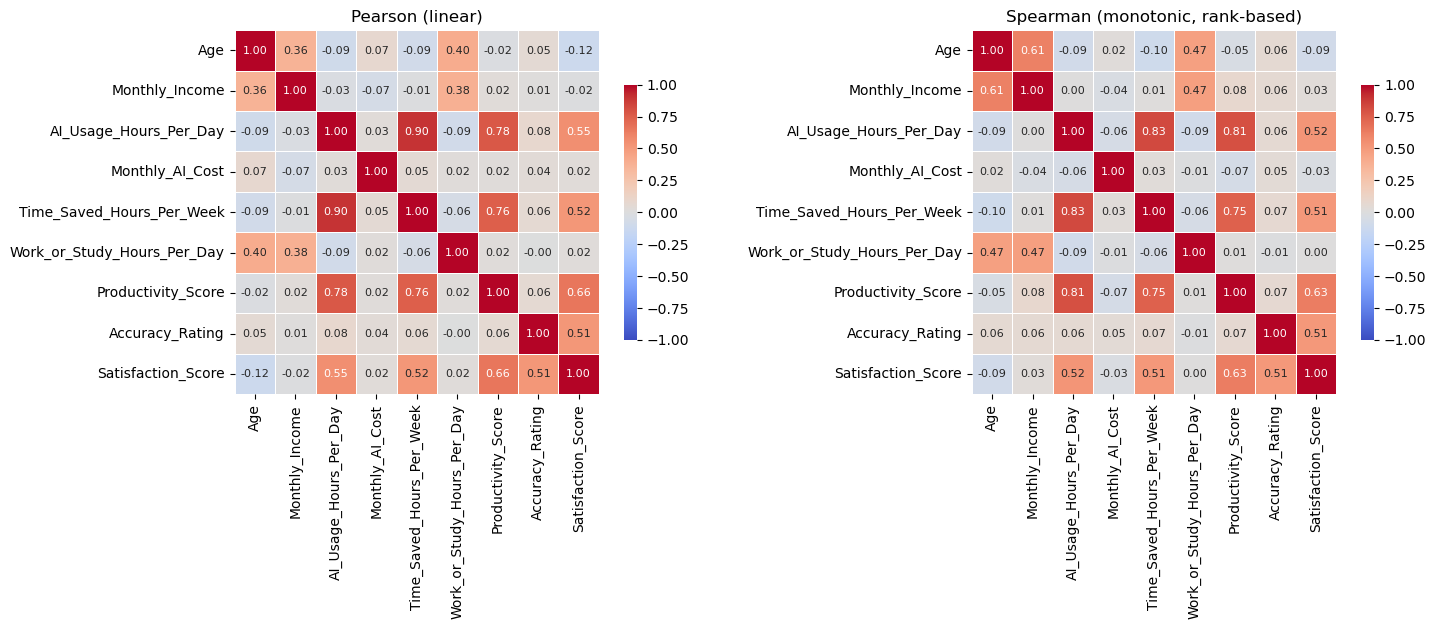

In [15]:
corr_p = df[num_cols].corr(method="pearson")
corr_s = df[num_cols].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cm, t in zip(axes, [corr_p, corr_s], ["Pearson (linear)", "Spearman (monotonic, rank-based)"]):
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax,
                square=True, cbar_kws={"shrink": 0.7}, annot_kws={"size": 8}, linewidths=0.5, linecolor="white")
    ax.set_title(t); ax.grid(False)
plt.tight_layout(); plt.show()

### 7.6 Formal hypothesis tests

In [16]:
res = []
# Student vs Professional (Mann-Whitney U, non-parametric because the score is bounded/ordinal-like)
a = df.loc[df.User_Type == "Student", "Productivity_Score"]; b = df.loc[df.User_Type == "Professional", "Productivity_Score"]
u = stats.mannwhitneyu(a, b)
res.append(("Student vs Professional", "Mann-Whitney U", u.statistic, u.pvalue))

# groups with >=2 levels: Kruskal-Wallis
for c in ["AI_Tool", "AI_Purpose", "Profession_Family", "Education_Level", "Country", "Gender"]:
    groups = [g["Productivity_Score"].values for _, g in df.groupby(c) if len(g) >= 5]
    h = stats.kruskal(*groups)
    res.append((c, "Kruskal-Wallis H", h.statistic, h.pvalue))

# numeric: Spearman rho against the target
for c in [x for x in num_cols if x != "Productivity_Score"]:
    ok = df[[c, "Productivity_Score"]].dropna()
    r = stats.spearmanr(ok[c], ok["Productivity_Score"])
    res.append((c, "Spearman rho", r.statistic, r.pvalue))

tests = pd.DataFrame(res, columns=["variable", "test", "statistic", "p_value"])
# Benjamini-Hochberg false-discovery-rate correction (many tests -> some will be "significant" by chance)
p = tests.p_value.values; order = np.argsort(p); m = len(p)
q = np.empty(m); q[order] = np.minimum.accumulate((p[order] * m / (np.arange(m) + 1))[::-1])[::-1]
tests["q_value_BH"] = np.minimum(q, 1)
tests["significant_5pct_FDR"] = tests.q_value_BH < 0.05
display(tests.sort_values("p_value"))

,variable,test,statistic,p_value,q_value_BH,significant_5pct_FDR
9,AI_Usage_Hours_Per_Day,Spearman rho,0.809,0.000,0.000,True
11,Time_Saved_Hours_Per_Week,Spearman rho,0.747,0.000,0.000,True
14,Satisfaction_Score,Spearman rho,0.632,0.000,0.000,True
8,Monthly_Income,Spearman rho,0.079,0.204,0.641,False
10,Monthly_AI_Cost,Spearman rho,-0.068,0.271,0.641,False
13,Accuracy_Rating,Spearman rho,0.067,0.279,0.641,False
5,Country,Kruskal-Wallis H,12.909,0.299,0.641,False
7,Age,Spearman rho,-0.045,0.477,0.826,False
0,Student vs Professional,Mann-Whitney U,8964.500,0.540,0.826,False
3,Profession_Family,Kruskal-Wallis H,5.570,0.591,0.826,False


**EDA key findings**

* **Daily AI usage hours is by far the strongest correlate of productivity** (Spearman ρ ≈ 0.8), followed by weekly time saved (≈ 0.75) and satisfaction (≈ 0.6). All three survive Benjamini–Hochberg FDR correction.
* **Who the user is barely matters**: student vs professional, tool (ChatGPT vs Claude vs Gemini…), purpose, profession family, education, country, gender, age and income show **no significant difference** after FDR correction.
* **Perceived accuracy is not linked to productivity** (ρ ≈ 0.07): the benefit comes from *engagement*, not from believing the AI is more accurate.
* Income and AI cost are extremely skewed (one data-entry error of 250,000/month was removed by the plausibility rule) → log transforms.
* *Correlation ≠ causation*: heavy users may be more productive because of AI, or already-productive people may simply use AI more.

Note the Benjamini–Hochberg correction: with ~15 tests, a raw p<0.05 alone is weak evidence.

## 8. Feature Engineering (with the maths)

All features in this section are **row-wise functions** of a single respondent's own answers, so they cannot leak information between train and test. Anything that needs to *learn* a statistic (scaling, TF-IDF vocabulary, PCA) is deferred to the pipeline.

| Feature | Formula | Why |
|---|---|---|
| `log_income`, `log_cost` | $\log(1+x)$ | Compresses right-skew; defined at $x=0$ (many students have 0 income / cost) |
| `ai_hours_log` | $\log(1+h)$ | Models **diminishing returns** of extra AI hours (concave) |
| `ai_hours_sq` | $h^2$ | Allows the opposite: an *inverted-U* (too much AI use hurts) |
| `ai_share` | $\min\!\left(\dfrac{h_{AI}}{h_{work}},\,1.5\right)$ | Fraction of the working/study day involving AI (intensity, scale-free) |
| `cost_income_ratio` | $\dfrac{c}{1+I}$ | Affordability burden of paying for AI |
| `is_paid` | $\mathbb 1[c>0]$ | Paid vs free tiers |
| `edu_rank` | ordinal 1–6 | Preserves the natural order High School < Diploma < Undergraduate < Bachelor's < Master's < PhD |
| `n_tasks`, `task_words`, `task_chars` | counts from `Tasks_Performed` | Breadth/richness of use |
| TF-IDF → SVD (in pipeline) | $X \approx U_k\Sigma_k V_k^\top$ | Latent "topics" of what people do with AI |
| `time_saved_per_ai_hour` *(outcome set)* | $\dfrac{T_{saved}/7}{h_{AI}}$ | Return on AI time invested (clipped at 5) |

The **TF-IDF weight** of term $t$ in document $d$ is
$$\text{tfidf}(t,d)=\text{tf}(t,d)\cdot\left(\ln\frac{1+N}{1+\text{df}(t)}+1\right)$$
(rare terms count more), and **truncated SVD** keeps the $k$ largest singular values, projecting the sparse term space onto $k$ dense latent dimensions.

In [17]:
fe = df.copy()

# ---- categorical: explicit "Unknown" (constant fill -> no leakage) ----
cat_cols = ["Gender", "Country", "User_Type", "AI_Tool", "AI_Purpose", "Profession_Family"]
for c in cat_cols:
    fe[c] = fe[c].astype(object).where(fe[c].notna(), "Unknown")

# ---- ordinal education ----
EDU_ORDER = {"High School": 1, "Diploma": 2, "Undergraduate": 3, "Bachelor's": 4, "Master's": 5, "PhD": 6}
fe["edu_rank"] = fe["Education_Level"].map(EDU_ORDER)           # NaN stays NaN -> imputed in pipeline

# ---- log transforms: log(1+x) ----
fe["log_income"] = np.log1p(fe["Monthly_Income"])
fe["log_cost"]   = np.log1p(fe["Monthly_AI_Cost"])
fe["ai_hours_log"] = np.log1p(fe["AI_Usage_Hours_Per_Day"])
fe["ai_hours_sq"]  = fe["AI_Usage_Hours_Per_Day"] ** 2

# ---- ratios ----
fe["ai_share"] = (fe["AI_Usage_Hours_Per_Day"] / fe["Work_or_Study_Hours_Per_Day"].replace(0, np.nan)).clip(upper=1.5)
fe["cost_income_ratio"] = fe["Monthly_AI_Cost"] / (1 + fe["Monthly_Income"])
fe["is_paid"] = (fe["Monthly_AI_Cost"] > 0).astype(float).where(fe["Monthly_AI_Cost"].notna())

# ---- free-text statistics ----
txt = fe["Tasks_Performed"].fillna("")
fe["Tasks_Performed"] = txt
fe["n_tasks"]    = txt.map(lambda s: 0 if s == "" else len([t for t in re.split(r",|;", s) if t.strip()]))
fe["task_words"] = txt.str.split().map(len)
fe["task_chars"] = txt.str.len()
fe["tasks_missing"] = (txt == "").astype(int)

# ---- outcome-side feature ----
fe["time_saved_per_ai_hour"] = ((fe["Time_Saved_Hours_Per_Week"] / 7) / fe["AI_Usage_Hours_Per_Day"].replace(0, np.nan)).clip(upper=5)

display(fe[["log_income", "log_cost", "ai_hours_log", "ai_hours_sq", "ai_share", "cost_income_ratio",
            "is_paid", "edu_rank", "n_tasks", "task_words", "time_saved_per_ai_hour"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
log_income,263.000,5.726,2.551,0.000,4.705,6.263,7.392,9.241
log_cost,262.000,1.397,1.530,0.000,0.000,0.000,3.045,4.615
ai_hours_log,266.000,1.220,0.511,0.405,0.833,1.099,1.624,2.389
ai_hours_sq,266.000,13.016,19.500,0.250,1.690,4.000,16.607,98.010
ai_share,257.000,0.423,0.338,0.048,0.175,0.306,0.558,1.500
cost_income_ratio,252.000,1.086,4.432,0.000,0.000,0.000,0.037,30.000
is_paid,262.000,0.466,0.500,0.000,0.000,0.000,1.000,1.000
edu_rank,263.000,3.350,1.459,1.000,2.000,4.000,4.000,6.000
n_tasks,274.000,3.299,0.933,0.000,3.000,3.000,4.000,4.000
task_words,274.000,18.449,5.998,0.000,16.000,19.000,22.000,33.000


In [18]:
# Did the log transform reduce skew?  (skewness should move towards 0)
cmp = pd.DataFrame({
    "raw skew": [fe["Monthly_Income"].skew(), fe["Monthly_AI_Cost"].skew(), fe["AI_Usage_Hours_Per_Day"].skew()],
    "log1p skew": [fe["log_income"].skew(), fe["log_cost"].skew(), fe["ai_hours_log"].skew()],
}, index=["income", "AI cost", "AI hours"])
display(cmp)

# Does the engineered feature carry more signal than the raw one? (Spearman with the target)
chk = {c: stats.spearmanr(fe[[c, "Productivity_Score"]].dropna()[c], fe[[c, "Productivity_Score"]].dropna()["Productivity_Score"]).statistic
       for c in ["AI_Usage_Hours_Per_Day", "ai_hours_log", "ai_share", "Monthly_Income", "log_income", "cost_income_ratio",
                 "n_tasks", "task_words", "edu_rank"]}
display(pd.Series(chk, name="Spearman rho with target").to_frame())

,raw skew,log1p skew
income,1.905,-1.137
AI cost,2.535,0.264
AI hours,1.294,0.388


,Spearman rho with target
AI_Usage_Hours_Per_Day,0.809
ai_hours_log,0.809
ai_share,0.748
Monthly_Income,0.079
log_income,0.079
cost_income_ratio,-0.120
n_tasks,-0.040
task_words,0.021
edu_rank,-0.041


> Spearman is rank-based, so monotonic transforms such as $\log(1+x)$ leave it **unchanged** – the benefit of logs is for *linear/distance-based models* (they see a less skewed, less outlier-dominated input), not for the rank correlation itself.

## 9. Train/Test Split & Leakage-Safe Preprocessing

**Rule:** split first → learn everything from the training set only → apply to test.
The test set is touched **exactly once**, at the very end.

### Feature sets (defined by *when the information exists*)

* **Set A – "Context"** (profile + usage behaviour): known before/independently of the productivity outcome. This is the **deployable, leak-free** feature set.
* **Set B – "Context + perceived outcomes"**: adds `Accuracy_Rating`, `Satisfaction_Score`, `Time_Saved_Hours_Per_Week` (+ its ratio). These are *co-outcomes of the same survey response* – they are measured at the same moment as the target and are partly consequences of the same underlying "AI worked well for me" experience. Using them to "predict" productivity is **target-adjacent leakage** (high score, little practical value). We build B only to **measure** how much it inflates performance (see §16).

In [19]:
TARGET = "Productivity_Score"
num_context = ["Age", "Monthly_Income", "log_income", "AI_Usage_Hours_Per_Day", "ai_hours_log", "ai_hours_sq",
               "Work_or_Study_Hours_Per_Day", "ai_share", "ai_exceeds_work_hours", "Monthly_AI_Cost", "log_cost",
               "cost_income_ratio", "is_paid", "edu_rank", "n_tasks", "task_words", "task_chars", "tasks_missing"]
num_outcome = ["Accuracy_Rating", "Satisfaction_Score", "Time_Saved_Hours_Per_Week", "time_saved_per_ai_hour"]
TEXT_COL = "Tasks_Performed"

feat_A = num_context + cat_cols + [TEXT_COL]
feat_B = num_context + num_outcome + cat_cols + [TEXT_COL]

X_all, y_all = fe[feat_B], fe[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED,
                                                    stratify=fe["User_Type"])
print(f"train {X_train.shape} | test {X_test.shape}")
print("target mean  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))
print("User_Type share  train:", X_train["User_Type"].value_counts(normalize=True).round(2).to_dict(),
      "| test:", X_test["User_Type"].value_counts(normalize=True).round(2).to_dict())

train (219, 29) | test (55, 29)
target mean  train: 5.091 | test: 5.807
User_Type share  train: {'Student': 0.52, 'Professional': 0.48} | test: {'Student': 0.53, 'Professional': 0.47}


In [20]:
def make_preprocessor(num_features, scaler="standard", text=True, n_svd=8):
    """ColumnTransformer: every fitted step (imputer, scaler, encoder, TF-IDF, SVD) learns from the TRAINING data only."""
    scalers = {"standard": StandardScaler(), "robust": RobustScaler(),
               "power": PowerTransformer(method="yeo-johnson", standardize=True), "none": "passthrough"}
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", scalers[scaler])])
    cat_pipe = OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False)
    parts = [("num", num_pipe, num_features), ("cat", cat_pipe, cat_cols)]
    if text:
        txt_pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=400, stop_words="english")),
                             ("svd", TruncatedSVD(n_components=n_svd, random_state=SEED)),
                             ("scale", StandardScaler())])
        parts.append(("txt", txt_pipe, TEXT_COL))   # string (not list) -> 1-D text input
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)

# --- inspect what the preprocessor produces (fit on TRAIN only) ---
pre_demo = make_preprocessor(num_context)
Xt_demo = pd.DataFrame(pre_demo.fit_transform(X_train[feat_A]), columns=pre_demo.get_feature_names_out(),
                       index=X_train.index)
print("Transformed training matrix:", Xt_demo.shape)
display(Xt_demo.iloc[:3, :12])

Transformed training matrix: (219, 84)


,Age,Monthly_Income,log_income,AI_Usage_Hours_Per_Day,ai_hours_log,ai_hours_sq,Work_or_Study_Hours_Per_Day,ai_share,ai_exceeds_work_hours,Monthly_AI_Cost,log_cost,cost_income_ratio
197,-0.123,-0.525,0.086,-0.558,-0.486,-0.509,0.352,-0.624,-0.290,0.063,0.708,-0.242
91,0.246,-0.464,0.198,2.148,1.849,2.186,-0.355,2.123,3.447,7.108,2.180,-0.203
84,-1.230,-0.651,-0.379,-0.992,-1.350,-0.622,-0.681,-0.887,-0.290,-0.720,-0.884,-0.248


## 10. Scaling / Normalisation

Distance- and gradient-based models (KNN, SVR, Ridge/Lasso) are sensitive to feature scale; trees are not. Three options are compared:

$$\textbf{Standard: } z=\frac{x-\mu}{\sigma}\qquad
\textbf{Robust: } z=\frac{x-\text{median}}{Q_3-Q_1}\qquad
\textbf{Yeo-Johnson: } \psi(x,\lambda)=\begin{cases}\frac{(x+1)^\lambda-1}{\lambda}&x\ge0,\lambda\ne0\\ \ln(x+1)&x\ge0,\lambda=0\\ -\frac{(1-x)^{2-\lambda}-1}{2-\lambda}&x<0,\lambda\ne2\\ -\ln(1-x)&x<0,\lambda=2\end{cases}$$

Yeo-Johnson chooses $\lambda$ per feature by maximum likelihood to make the distribution as Gaussian as possible, and (unlike Box-Cox) handles zeros/negatives.

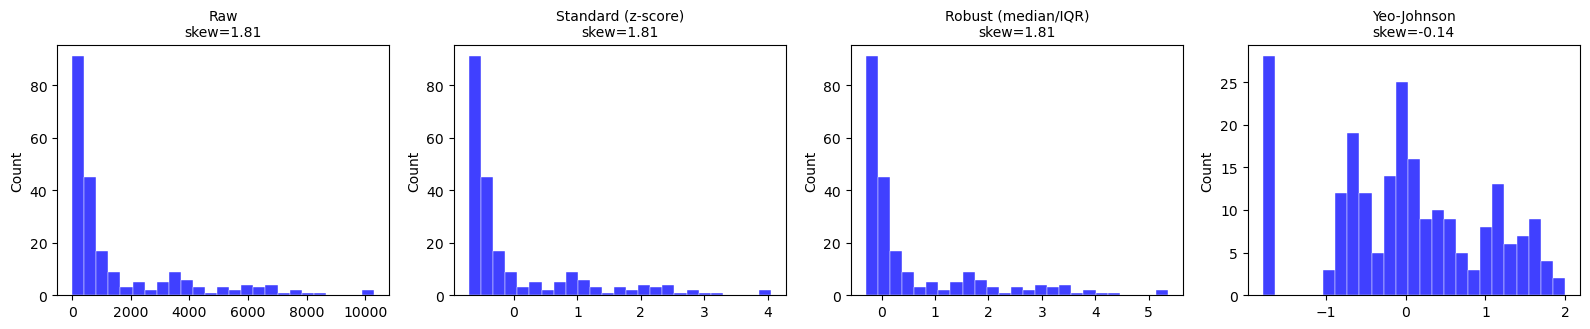

In [21]:
# Visual check on a skewed feature: Monthly_Income (training data only)
inc = X_train[["Monthly_Income"]].copy()
inc = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(inc), columns=["Monthly_Income"])
variants = {
    "Raw": inc.values.ravel(),
    "Standard (z-score)": StandardScaler().fit_transform(inc).ravel(),
    "Robust (median/IQR)": RobustScaler().fit_transform(inc).ravel(),
    "Yeo-Johnson": PowerTransformer("yeo-johnson").fit_transform(inc).ravel(),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (k, v) in zip(axes, variants.items()):
    sns.histplot(v, bins=25, color="#0000FF", ax=ax, edgecolor="white", linewidth=0.3)
    ax.set_title(f"{k}\nskew={stats.skew(v):.2f}", fontsize=10)
plt.tight_layout(); plt.show()

In [22]:
# Which scaler is best for the scale-sensitive models?  (CV on the training set; no test data used)
cv_fast = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for sc in ["none", "standard", "robust", "power"]:
    for name, mdl in [("Ridge(alpha=10)", Ridge(alpha=10)), ("SVR(C=3)", SVR(C=3)), ("KNN(k=10)", KNeighborsRegressor(10))]:
        pipe = Pipeline([("pre", make_preprocessor(num_context, scaler=sc)), ("m", mdl)])
        s = cross_val_score(pipe, X_train[feat_A], y_train, cv=cv_fast, scoring="neg_root_mean_squared_error", n_jobs=-1)
        rows.append((sc, name, -s.mean()))
sc_tab = pd.DataFrame(rows, columns=["scaler", "model", "CV RMSE"]).pivot(index="scaler", columns="model", values="CV RMSE")
display(sc_tab.round(4))
BEST_SCALER = sc_tab.drop(index="none").mean(axis=1).idxmin()      # lowest average CV RMSE across the 3 scale-sensitive models
print("Average CV RMSE per scaler:", sc_tab.mean(axis=1).round(3).to_dict())
print("Chosen scaler:", BEST_SCALER, "(data-driven; tree models are scale-invariant so it only matters for linear/KNN/SVR)")

model,KNN(k=10),Ridge(alpha=10),SVR(C=3)
scaler,,,
none,1.669,1.206,1.733
power,1.294,1.249,1.248
robust,1.407,1.205,1.655
standard,1.381,1.238,1.274


Average CV RMSE per scaler: {'none': 1.536, 'power': 1.264, 'robust': 1.422, 'standard': 1.298}
Chosen scaler: power (data-driven; tree models are scale-invariant so it only matters for linear/KNN/SVR)


## 11. Feature Reduction

With ~230 training rows and ~50+ encoded columns, dimensionality is a real risk (variance $\propto p/n$). We inspect redundancy four ways. **All statistics below use the training matrix only.**

1. **Zero/near-zero variance filter**
2. **Pairwise correlation** (|r| > 0.85 ⇒ redundant)
3. **Variance Inflation Factor**: $\;\text{VIF}_j=\dfrac{1}{1-R_j^2}=\big[R^{-1}\big]_{jj}$ where $R$ is the correlation matrix (VIF>10 ⇒ severe multicollinearity)
4. **PCA** – eigen-decomposition of the covariance matrix $\Sigma=V\Lambda V^\top$; explained variance of component $i$ is $\lambda_i/\sum_j\lambda_j$

In [23]:
Xt = Xt_demo.copy()
print("Encoded feature count:", Xt.shape[1])

# 1) variance filter
vt = VarianceThreshold(threshold=1e-6).fit(Xt)
dropped_var = Xt.columns[~vt.get_support()].tolist()
print("Zero-variance columns:", dropped_var)
Xt = Xt.loc[:, vt.get_support()]

# 2) high-correlation pairs
cm = Xt.corr().abs()
upper = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("\nPairs with |r| > 0.85:")
display(pairs[pairs > 0.85].to_frame("|r|"))

Encoded feature count: 84
Zero-variance columns: []

Pairs with |r| > 0.85:


,,|r|
User_Type_Professional,User_Type_Student,1.000
missingindicator_AI_Usage_Hours_Per_Day,missingindicator_ai_hours_log,1.000
missingindicator_Monthly_Income,missingindicator_log_income,1.000
missingindicator_AI_Usage_Hours_Per_Day,missingindicator_ai_hours_sq,1.000
missingindicator_Monthly_AI_Cost,missingindicator_log_cost,1.000
missingindicator_log_cost,missingindicator_is_paid,1.000
missingindicator_Monthly_AI_Cost,missingindicator_is_paid,1.000
missingindicator_ai_hours_log,missingindicator_ai_hours_sq,1.000
log_cost,is_paid,0.983
AI_Usage_Hours_Per_Day,ai_hours_log,0.964


In [24]:
# 3) VIF from the inverse correlation matrix (numeric block only)
num_block = Xt[[c for c in Xt.columns if c in num_context]]
R = np.corrcoef(num_block.values, rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(R)), index=num_block.columns).sort_values(ascending=False)
display(vif.round(1).to_frame("VIF").head(12))
print("Features with VIF > 10:", vif[vif > 10].index.tolist())

,VIF
AI_Usage_Hours_Per_Day,422.600
log_cost,175.600
ai_hours_log,128.100
is_paid,103.200
ai_hours_sq,103.100
ai_share,19.600
task_chars,18.700
Monthly_AI_Cost,17.000
task_words,15.300
tasks_missing,4.700


Features with VIF > 10: ['AI_Usage_Hours_Per_Day', 'log_cost', 'ai_hours_log', 'is_paid', 'ai_hours_sq', 'ai_share', 'task_chars', 'Monthly_AI_Cost', 'task_words']


High VIFs are expected: by construction `AI_Usage_Hours_Per_Day`, its log and its square carry overlapping information, as do income vs log-income. This **hurts coefficient stability in OLS** but **not predictive accuracy of regularised or tree models**, which is why we later prefer Ridge/ElasticNet/trees (regularisation shrinks along the correlated directions) instead of hand-deleting columns.

max |manual - sklearn| explained-variance ratio: 0.0


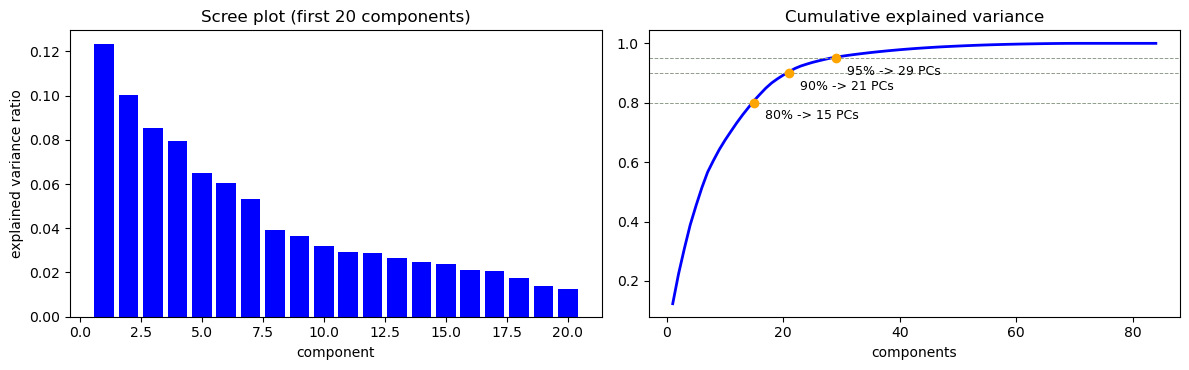

84 features -> 15 PCs retain 80%, 21 retain 90%, 29 retain 95% of variance


In [25]:
# 4) PCA: manual eigen-decomposition vs scikit-learn (they must agree)
Z = Xt.values - Xt.values.mean(0)
cov = np.cov(Z, rowvar=False)
eigval, eigvec = np.linalg.eigh(cov)
idx = np.argsort(eigval)[::-1]; eigval, eigvec = eigval[idx], eigvec[:, idx]
evr_manual = eigval / eigval.sum()

pca = PCA().fit(Xt.values)
print("max |manual - sklearn| explained-variance ratio:", np.abs(evr_manual - pca.explained_variance_ratio_).max().round(12))

cum = np.cumsum(pca.explained_variance_ratio_)
k80, k90, k95 = [int(np.searchsorted(cum, t) + 1) for t in (0.80, 0.90, 0.95)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(1, 21), pca.explained_variance_ratio_[:20], color="#0000FF")
ax[0].set_title("Scree plot (first 20 components)"); ax[0].set_xlabel("component"); ax[0].set_ylabel("explained variance ratio")
ax[1].plot(range(1, len(cum) + 1), cum, color="#0000FF", lw=2)
for t, k in [(0.8, k80), (0.9, k90), (0.95, k95)]:
    ax[1].axhline(t, color="#8F9C8B", lw=0.7, ls="--"); ax[1].scatter([k], [t], color="#FFA500", zorder=3)
    ax[1].annotate(f"{int(t*100)}% -> {k} PCs", (k, t), textcoords="offset points", xytext=(8, -12), fontsize=9)
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("components")
plt.tight_layout(); plt.show()
print(f"{Xt.shape[1]} features -> {k80} PCs retain 80%, {k90} retain 90%, {k95} retain 95% of variance")

max |closed-form - sklearn| coefficient difference: 0.0


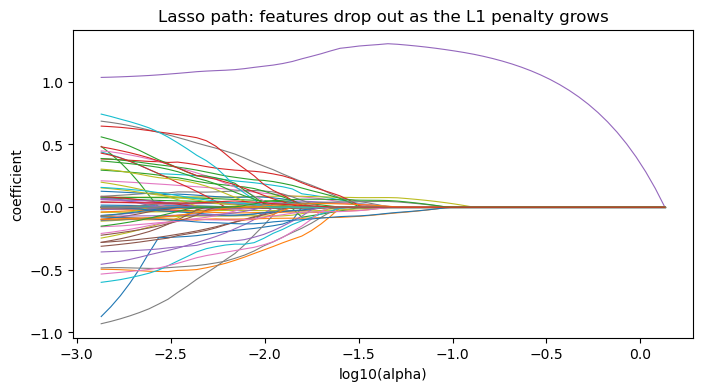

In [26]:
# Ridge closed form, verified by hand:  beta = (X'X + lambda*I)^-1 X'y   (on centred data, no intercept penalty)
Xc = Xt.values - Xt.values.mean(0); yc = y_train.values - y_train.values.mean()
lam = 10.0
beta_closed = np.linalg.solve(Xc.T @ Xc + lam * np.eye(Xc.shape[1]), Xc.T @ yc)
ridge = Ridge(alpha=lam, fit_intercept=True).fit(Xt.values, y_train.values)
print("max |closed-form - sklearn| coefficient difference:", np.abs(beta_closed - ridge.coef_).max().round(10))

# Lasso path: coefficients hitting exactly zero = automatic feature selection (L1)
alphas, coefs, _ = lasso_path(Xc, yc, n_alphas=60)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.log10(alphas), coefs.T, lw=0.8)
ax.set_xlabel("log10(alpha)"); ax.set_ylabel("coefficient"); ax.set_title("Lasso path: features drop out as the L1 penalty grows")
plt.show()

**Reduction strategy decision.** We will not hand-delete columns. Instead we treat reduction as a *modelling choice evaluated by cross-validation* (§12): compare **(i)** all features, **(ii)** PCA (95% variance) and **(iii)** L1 (Lasso) selection, each *inside* the CV loop.

## 12. Model Comparison (Regression)

**Metrics**

$$\text{RMSE}=\sqrt{\tfrac1n\sum(y_i-\hat y_i)^2},\quad \text{MAE}=\tfrac1n\sum|y_i-\hat y_i|,\quad R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$$

$R^2=0$ means "no better than predicting the training mean" (the `Dummy` baseline). **Repeated 5-fold CV × 3** gives 15 train/validation scores per model → mean and spread.
`train − CV` gap is our over-fitting alarm.

In [27]:
def make_models():
    return {
        "Dummy (mean)": DummyRegressor(),
        "OLS": LinearRegression(),
        "Ridge": Ridge(alpha=10),
        "Lasso": Lasso(alpha=0.05, max_iter=50000),
        "ElasticNet": ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=50000),
        "KNN": KNeighborsRegressor(n_neighbors=10, weights="distance"),
        "SVR (RBF)": SVR(C=3, epsilon=0.2),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, random_state=SEED, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=SEED),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, max_depth=3, min_samples_leaf=10, random_state=SEED),
    }

SCORING = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def compare(features, num_features, label, reducer=None, models=None):
    rows = []
    for name, mdl in (models or make_models()).items():
        steps = [("pre", make_preprocessor(num_features, scaler=BEST_SCALER))]
        if reducer == "pca":   steps.append(("red", PCA(n_components=0.95, random_state=SEED)))
        if reducer == "lasso": steps.append(("red", SelectFromModel(Lasso(alpha=0.03, max_iter=50000), threshold=1e-8)))
        steps.append(("m", mdl))
        r = cross_validate(Pipeline(steps), X_train[features], y_train, cv=cv, scoring=SCORING,
                           return_train_score=True, n_jobs=-1)
        rows.append({"feature_set": label, "reduction": reducer or "none", "model": name,
                     "CV_R2": r["test_r2"].mean(), "CV_R2_std": r["test_r2"].std(),
                     "Train_R2": r["train_r2"].mean(), "gap(train-CV)": r["train_r2"].mean() - r["test_r2"].mean(),
                     "CV_RMSE": -r["test_rmse"].mean(), "CV_MAE": -r["test_mae"].mean()})
    return pd.DataFrame(rows)

res_A = compare(feat_A, num_context, "A: context (leak-free)")
display(res_A.drop(columns=["feature_set", "reduction"]).sort_values("CV_RMSE").round(3).reset_index(drop=True))

,model,CV_R2,CV_R2_std,Train_R2,gap(train-CV),CV_RMSE,CV_MAE
0,Random Forest,0.567,0.121,0.883,0.315,1.091,0.910
1,Lasso,0.543,0.169,0.640,0.097,1.117,0.908
2,Extra Trees,0.542,0.121,0.927,0.385,1.124,0.933
3,HistGradientBoosting,0.512,0.141,0.915,0.403,1.158,0.966
4,ElasticNet,0.504,0.194,0.661,0.157,1.160,0.942
5,Gradient Boosting,0.499,0.145,0.891,0.392,1.173,0.974
6,SVR (RBF),0.441,0.176,0.913,0.472,1.240,1.017
7,Ridge,0.428,0.210,0.710,0.281,1.249,1.018
8,KNN,0.409,0.106,1.000,0.591,1.291,1.034
9,OLS,0.149,0.274,0.757,0.608,1.532,1.239


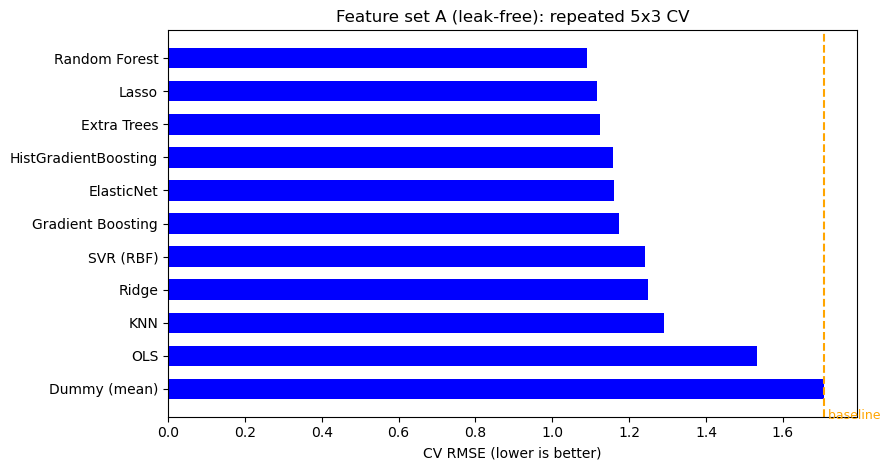

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.8))

d = res_A.sort_values("CV_RMSE", ascending=False)

ax.barh(d["model"], d["CV_RMSE"], xerr=None, color= "#0000FF", height=0.62)

ax.axvline(res_A.loc[res_A.model == "Dummy (mean)", "CV_RMSE"].iloc[0], color="#FFA500", lw=1.5, ls="--")

ax.text(res_A.loc[res_A.model == "Dummy (mean)", "CV_RMSE"].iloc[0], -0.9, " baseline", color="#FFA500", fontsize=9)

ax.set_xlabel("CV RMSE (lower is better)"); ax.set_title("Feature set A (leak-free): repeated 5x3 CV")

plt.tight_layout(); plt.show()

### 12.1 Does feature reduction help? (PCA vs L1 selection vs none)

In [29]:
sel_models = {k: v for k, v in make_models().items() if k in ["Ridge", "Random Forest", "Gradient Boosting", "SVR (RBF)"]}

red_tab = pd.concat([compare(feat_A, num_context, "A", reducer=r, models=sel_models) for r in [None, "pca", "lasso"]])

display(red_tab.pivot(index="model", columns="reduction", values="CV_RMSE").round(4))

reduction,lasso,none,pca
model,,,
Gradient Boosting,1.198,1.173,1.232
Random Forest,1.107,1.091,1.200
Ridge,1.217,1.249,1.177
SVR (RBF),1.280,1.240,1.230


### 12.2 Leakage experiment: feature set B (adds the perceived-outcome columns)

In [30]:
res_B = compare(feat_B, num_context + num_outcome, "B: context + perceived outcomes")

both = pd.concat([res_A, res_B])

display(both.pivot(index="model", columns="feature_set", values="CV_R2").round(3))

feature_set,A: context (leak-free),B: context + perceived outcomes
model,,
Dummy (mean),-0.018,-0.018
ElasticNet,0.504,0.637
Extra Trees,0.542,0.609
Gradient Boosting,0.499,0.597
HistGradientBoosting,0.512,0.591
KNN,0.409,0.470
Lasso,0.543,0.657
OLS,0.149,0.369
Random Forest,0.567,0.618


## 13. Hyper-parameter Tuning & Nested Cross-Validation

Tuning on the same folds you report on gives an **optimistically biased** score. We therefore:

1. tune with `RandomizedSearchCV` / `GridSearchCV` (inner CV), and
2. estimate the *tuned procedure's* true performance with **nested CV** (outer folds never see the tuning).

The feature set used for the **primary, deployable model is A** (leak-free). Tuning is done for the top candidates.

In [31]:
import tempfile, joblib
_CACHE = joblib.Memory(tempfile.mkdtemp(), verbose=0)   # caches the (identical) preprocessing of each CV fold while we sweep model parameters.
                                                        # Keys are the fold's own training data, so this stays leakage-free and just saves time.
def pipe_for(model, num_features=num_context):
    return Pipeline([("pre", make_preprocessor(num_features, scaler=BEST_SCALER)), ("m", model)], memory=_CACHE)

search_spaces = {
    "Ridge": (Ridge(), {"m__alpha": np.logspace(-1, 3, 25)}, "grid"),
    "ElasticNet": (ElasticNet(max_iter=50000), {"m__alpha": np.logspace(-3, 0.5, 15), "m__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}, "grid"),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"m__max_depth": [3, 4, 6, 8, None], "m__min_samples_leaf": [2, 3, 5, 8, 12],
                       "m__max_features": [0.2, 0.35, 0.5, 0.75, 1.0]}, "random"),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=SEED, subsample=0.8),
                          {"m__n_estimators": [50, 100, 150, 250], "m__learning_rate": [0.02, 0.05, 0.1],
                           "m__max_depth": [1, 2, 3], "m__min_samples_leaf": [3, 5, 10, 15]}, "random"),
}
inner = KFold(5, shuffle=True, random_state=SEED)
tuned = {}
for name, (mdl, space, kind) in search_spaces.items():
    if kind == "grid":
        s = GridSearchCV(pipe_for(mdl), space, cv=inner, scoring="neg_root_mean_squared_error", n_jobs=-1)
    else:
        s = RandomizedSearchCV(pipe_for(mdl), space, n_iter=25, cv=inner, scoring="neg_root_mean_squared_error",
                               random_state=SEED, n_jobs=-1)
    s.fit(X_train[feat_A], y_train)
    tuned[name] = s
    print(f"{name:18s} inner-CV RMSE = {-s.best_score_:.4f}  best = { {k.replace('m__',''): v for k, v in s.best_params_.items()} }")

Ridge              inner-CV RMSE = 1.1735  best = {'alpha': np.float64(146.7799267622069)}
ElasticNet         inner-CV RMSE = 1.1011  best = {'alpha': np.float64(0.1778279410038923), 'l1_ratio': 0.9}
Random Forest      inner-CV RMSE = 1.0702  best = {'min_samples_leaf': 12, 'max_features': 0.75, 'max_depth': 4}
Gradient Boosting  inner-CV RMSE = 1.1085  best = {'n_estimators': 50, 'min_samples_leaf': 5, 'max_depth': 1, 'learning_rate': 0.1}


ElasticNet         inner-CV RMSE = 1.1011  best = {'alpha': np.float64(0.1778279410038923), 'l1_ratio': 0.9}


Random Forest      inner-CV RMSE = 1.0710  best = {'min_samples_leaf': 12, 'max_features': 0.75, 'max_depth': 4}


Gradient Boosting  inner-CV RMSE = 1.1103  best = {'n_estimators': 50, 'min_samples_leaf': 5, 'max_depth': 1, 'learning_rate': 0.1}


In [32]:
# Nested CV: outer folds are untouched by the inner search -> honest estimate of "tune + fit"
outer = KFold(5, shuffle=True, random_state=7)
nested = {}
for name, (mdl, space, kind) in search_spaces.items():
    if kind == "grid":
        s = GridSearchCV(pipe_for(mdl), space, cv=inner, scoring="neg_root_mean_squared_error", n_jobs=1)
    else:
        s = RandomizedSearchCV(pipe_for(mdl), space, n_iter=12, cv=KFold(3, shuffle=True, random_state=SEED),
                               scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=1)
    sc = cross_validate(s, X_train[feat_A], y_train, cv=outer, scoring=["r2", "neg_root_mean_squared_error"], n_jobs=-1)
    nested[name] = (sc["test_r2"].mean(), -sc["test_neg_root_mean_squared_error"].mean(), sc["test_r2"].std())
base_rmse = res_A.loc[res_A.model == "Dummy (mean)", "CV_RMSE"].iloc[0]
nest_tab = pd.DataFrame(nested, index=["nested_R2", "nested_RMSE", "R2_std"]).T.sort_values("nested_RMSE")
nest_tab["improvement_vs_baseline_%"] = (1 - nest_tab["nested_RMSE"] / base_rmse) * 100
display(nest_tab.round(3))
# Parsimony rule: among procedures within 0.01 RMSE of the best, prefer the simplest/most interpretable one
cands = nest_tab[nest_tab["nested_RMSE"] <= nest_tab["nested_RMSE"].min() + 0.01].index
BEST_NAME = next(n for n in ["Ridge", "ElasticNet", "Random Forest", "Gradient Boosting"] if n in cands)
print("Statistically tied candidates:", list(cands))
print("Selected tuned procedure on feature set A:", BEST_NAME)

,nested_R2,nested_RMSE,R2_std,improvement_vs_baseline_%
Random Forest,0.600,1.073,0.055,37.099
Gradient Boosting,0.592,1.084,0.048,36.453
ElasticNet,0.583,1.095,0.069,35.843
Ridge,0.552,1.132,0.083,33.692


Statistically tied candidates: ['Random Forest']
Selected tuned procedure on feature set A: Random Forest


## 14. Final Evaluation on the Untouched Test Set

The tuned model is refitted on the whole training set and scored **once** on the held-out 20%. We report a bootstrap confidence interval (1,000 resamples) because with ~58 test rows a single point estimate is noisy.

In [33]:
final_A = tuned[BEST_NAME].best_estimator_.fit(X_train[feat_A], y_train)
pred_A = final_A.predict(X_test[feat_A])

dummy = Pipeline([("pre", make_preprocessor(num_context)), ("m", DummyRegressor())]).fit(X_train[feat_A], y_train)
pred_dummy = dummy.predict(X_test[feat_A])

def report(y, p):
    return {"R2": r2_score(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p)}

rng = np.random.default_rng(SEED)
def boot_ci(y, p, fn, B=1000):
    y = np.asarray(y); p = np.asarray(p); vals = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y)); vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

tbl = pd.DataFrame({"Dummy baseline": report(y_test, pred_dummy), f"{BEST_NAME} (set A)": report(y_test, pred_A)}).T
tbl["R2 95% CI"] = ["" , str(np.round(boot_ci(y_test, pred_A, r2_score), 3))]
display(tbl.round(3))

,R2,RMSE,MAE,R2 95% CI
Dummy baseline,-0.116,2.222,1.777,
Random Forest (set A),0.601,1.328,1.013,[0.399 0.725]


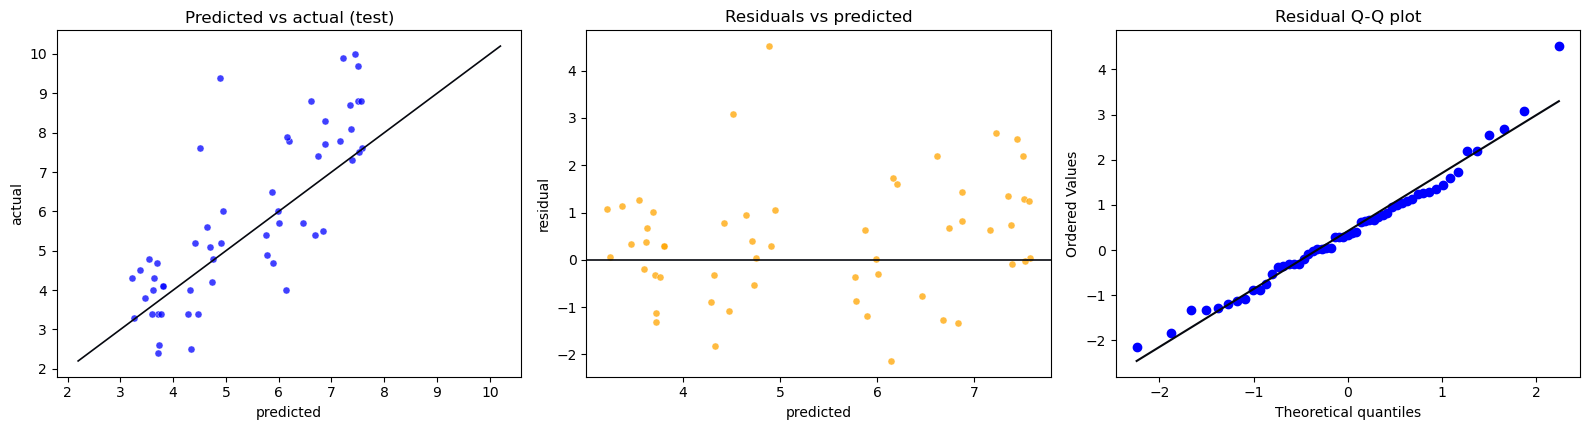

Residual mean: 0.420 | Shapiro p=0.318 | Breusch-Pagan-style check (|res| vs pred) Spearman rho=0.21


In [34]:
res = y_test.values - pred_A

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

ax[0].scatter(pred_A, y_test, s=26, color="#0000FF", alpha=0.75, edgecolor="white", linewidth=0.4)

lo, hi = min(y_test.min(), pred_A.min()) - .2, max(y_test.max(), pred_A.max()) + .2

ax[0].plot([lo, hi], [lo, hi], color="#06080F", lw=1.2); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("actual")

ax[0].set_title("Predicted vs actual (test)")

ax[1].scatter(pred_A, res, s=26, color="#FFA500", alpha=0.75, edgecolor="white", linewidth=0.4)

ax[1].axhline(0, color="#06080F", lw=1.2); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals vs predicted")

stats.probplot(res, dist="norm", plot=ax[2]); ax[2].get_lines()[0].set_color("#0000FF"); ax[2].get_lines()[1].set_color("#06080F")

ax[2].set_title("Residual Q-Q plot")

plt.tight_layout(); plt.show()

print("Residual mean: %.3f | Shapiro p=%.3f | Breusch-Pagan-style check (|res| vs pred) Spearman rho=%.2f" %
      (res.mean(), stats.shapiro(res).pvalue, stats.spearmanr(pred_A, np.abs(res)).statistic))

In [35]:
# For reference: the same procedure on feature set B (NOT deployable, shown to quantify leakage)
final_B = Pipeline([("pre", make_preprocessor(num_context + num_outcome, scaler=BEST_SCALER)),
                    ("m", clone(tuned[BEST_NAME].best_estimator_.named_steps["m"]))]).fit(X_train[feat_B], y_train)
pred_B = final_B.predict(X_test[feat_B])
cmp_AB = pd.DataFrame({"Set A (context, deployable)": report(y_test, pred_A),
                       "Set B (+perceived outcomes)": report(y_test, pred_B)}).T
display(cmp_AB.round(3))

,R2,RMSE,MAE
"Set A (context, deployable)",0.601,1.328,1.013
Set B (+perceived outcomes),0.625,1.288,0.990


## 15. Under-fitting / Over-fitting Diagnosis

Expected error decomposes as $\;\mathbb E[(y-\hat f)^2]=\underbrace{\text{Bias}^2}_{\text{under-fit}}+\underbrace{\text{Var}}_{\text{over-fit}}+\sigma^2_{\text{noise}}$.

| Symptom | Diagnosis |
|---|---|
| train error high **and** CV error high, curves converge | high bias → **under-fitting** |
| train error low, CV error high, large gap | high variance → **over-fitting** |
| both similar and low; gap shrinking with more data | good fit |

Tools: **learning curve** (error vs training-set size), **validation curve** (error vs complexity), and the train-vs-CV gap table.

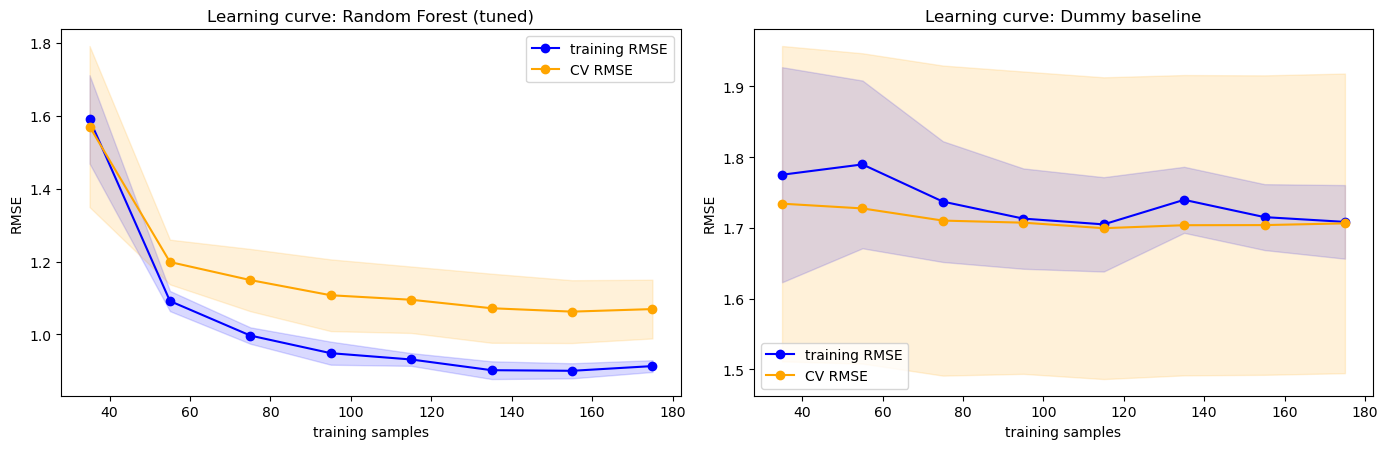

In [36]:
sizes = np.linspace(0.2, 1.0, 8)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (nm, mdl) in zip(axes, [(f"{BEST_NAME} (tuned)", final_A), ("Dummy baseline", dummy)]):
    ts, tr, va = learning_curve(clone(mdl), X_train[feat_A], y_train, train_sizes=sizes,
                                cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error", n_jobs=-1)
    tr, va = -tr, -va
    ax.plot(ts, tr.mean(1), "-o", color="#0000FF", label="training RMSE"); ax.fill_between(ts, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), color="#0000FF", alpha=0.15)
    ax.plot(ts, va.mean(1), "-o", color="#FFA500", label="CV RMSE"); ax.fill_between(ts, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color="#FFA500", alpha=0.15)
    ax.set_title(f"Learning curve: {nm}"); ax.set_xlabel("training samples"); ax.set_ylabel("RMSE"); ax.legend()
plt.tight_layout(); plt.show()

In [37]:
BLUE = "#0000FF"
ORANGE = "#FFA500"

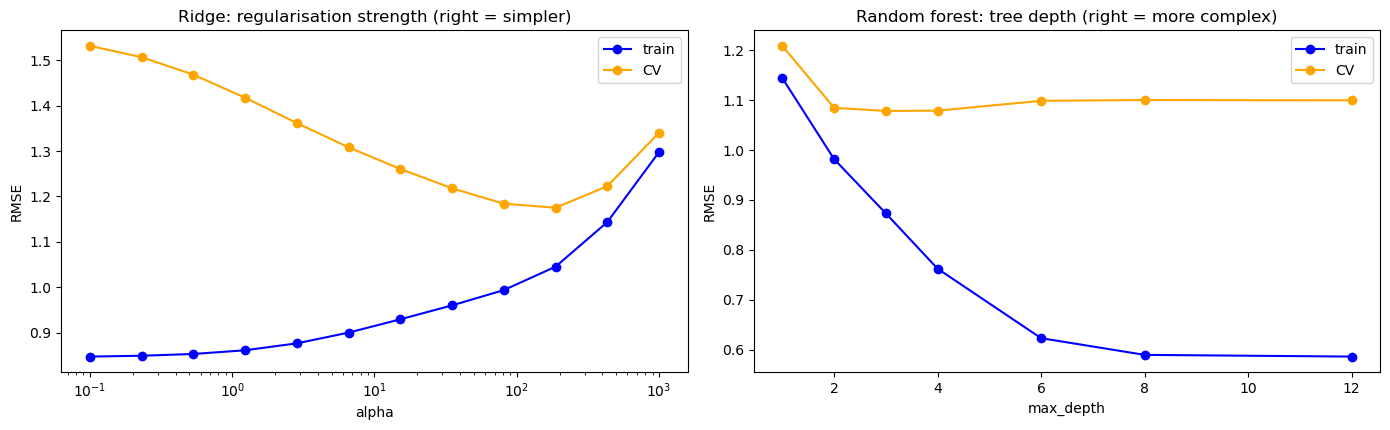

In [38]:
# Validation curves: sweep model complexity and watch train vs CV diverge
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
pr = np.logspace(-1, 3, 12)
tr, va = validation_curve(pipe_for(Ridge()), X_train[feat_A], y_train, param_name="m__alpha", param_range=pr,
                          cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error", n_jobs=-1)
axes[0].semilogx(pr, -tr.mean(1), "-o", color=BLUE, label="train"); axes[0].semilogx(pr, -va.mean(1), "-o", color=ORANGE, label="CV")
axes[0].set_title("Ridge: regularisation strength (right = simpler)"); axes[0].set_xlabel("alpha"); axes[0].set_ylabel("RMSE"); axes[0].legend()

pr2 = [1, 2, 3, 4, 6, 8, 12]
rf_pipe = pipe_for(RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5, random_state=SEED, n_jobs=-1))
tr, va = validation_curve(rf_pipe, X_train[feat_A], y_train, param_name="m__max_depth", param_range=pr2,
                          cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error", n_jobs=-1)
axes[1].plot(pr2, -tr.mean(1), "-o", color=BLUE, label="train"); axes[1].plot(pr2, -va.mean(1), "-o", color=ORANGE, label="CV")
axes[1].set_title("Random forest: tree depth (right = more complex)"); axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("RMSE"); axes[1].legend()
plt.tight_layout(); plt.show()

In [39]:
# Final verdict table: train vs CV vs test for the chosen model
cvres = cross_validate(final_A, X_train[feat_A], y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
fit_tab = pd.DataFrame({"R2": [cvres["train_r2"].mean(), cvres["test_r2"].mean(), r2_score(y_test, pred_A)],
                        "RMSE": [-cvres["train_rmse"].mean(), -cvres["test_rmse"].mean(), report(y_test, pred_A)["RMSE"]]},
                       index=["train (in-fold)", "CV (validation folds)", "TEST (hold-out)"])
display(fit_tab.round(3))
gap = fit_tab.loc["train (in-fold)", "R2"] - fit_tab.loc["CV (validation folds)", "R2"]
print(f"train-CV R2 gap = {gap:.3f}  |  CV-test R2 difference = {fit_tab.loc['CV (validation folds)','R2'] - fit_tab.loc['TEST (hold-out)','R2']:.3f}")

,R2,RMSE
train (in-fold),0.713,0.915
CV (validation folds),0.588,1.067
TEST (hold-out),0.601,1.328


train-CV R2 gap = 0.125  |  CV-test R2 difference = -0.013


## 16. Data-Leakage Audit

| Check | How it is guaranteed / tested |
|---|---|
| **1. Split before fitting** | `train_test_split` precedes every fitted step; imputer, scaler, encoder, TF-IDF, SVD, PCA, selectors are inside `Pipeline` → refit per CV fold |
| **2. Row-wise-only engineering** | features use only the respondent's own values (no group means, no target encoding) |
| **3. Target never imputed / used** | rows with missing target dropped; target not in X |
| **4. Duplicates across split** | tested below: exact-row overlap between train and test must be 0 |
| **5. Target-adjacent features** | feature set B vs A experiment quantifies the inflation; deployable model uses A |
| **6. Permutation (target-shuffle) test** | if the pipeline leaks, a model trained on *shuffled* targets would still score $R^2\gg0$; it should be ≈ 0 or negative |
| **7. Suspiciously strong single predictor** | scan for features whose |correlation| with the target is extreme |

In [40]:
# 4) duplicate / near-duplicate overlap between train and test
key = ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Tasks_Performed", "Country", "Profession_Family"]
tr_keys = set(map(tuple, X_train[key].astype(str).values)); te_keys = set(map(tuple, X_test[key].astype(str).values))
print("Test rows whose key-fields also appear in TRAIN:", len(tr_keys & te_keys), "(0 = clean)")
print("User_ID duplicated anywhere in the cleaned data:", int(df['User_ID'].duplicated().sum()))

# 7) strongest single-feature correlations with the target (train only)
tr_df = X_train[num_context + num_outcome].copy(); tr_df[TARGET] = y_train
c = tr_df.corr(method="spearman")[TARGET].drop(TARGET).abs().sort_values(ascending=False)
display(c.head(8).round(3).to_frame("|Spearman| with target (train)"))

Test rows whose key-fields also appear in TRAIN: 0 (0 = clean)
User_ID duplicated anywhere in the cleaned data: 0


,|Spearman| with target (train)
ai_hours_log,0.795
AI_Usage_Hours_Per_Day,0.795
ai_hours_sq,0.795
ai_share,0.736
Time_Saved_Hours_Per_Week,0.735
Satisfaction_Score,0.603
ai_exceeds_work_hours,0.379
Accuracy_Rating,0.094


In [41]:
MUTED = "#8F9C8B"

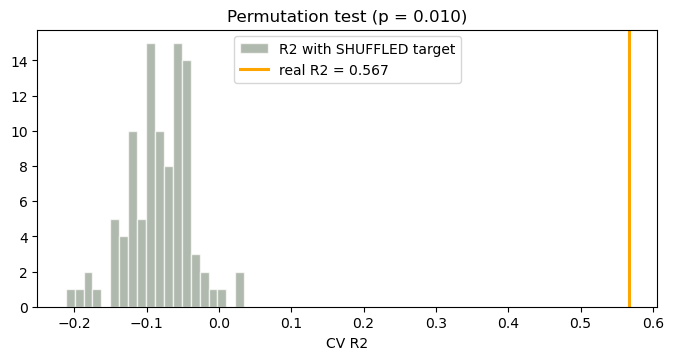

Mean R2 on shuffled targets: -0.083  (a leak-free pipeline should be <= 0)


In [42]:
# 6) permutation test on the leak-free pipeline: shuffle y 100x, refit with the SAME CV
score, perm_scores, pval = permutation_test_score(clone(final_A), X_train[feat_A], y_train, scoring="r2",
                                                  cv=KFold(5, shuffle=True, random_state=SEED), n_permutations=100,
                                                  random_state=SEED, n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(perm_scores, bins=20, color=MUTED, alpha=0.7, edgecolor="white", label="R2 with SHUFFLED target")
ax.axvline(score, color=ORANGE, lw=2.2, label=f"real R2 = {score:.3f}")
ax.set_title(f"Permutation test (p = {pval:.3f})"); ax.set_xlabel("CV R2"); ax.legend()
plt.show()
print(f"Mean R2 on shuffled targets: {perm_scores.mean():.3f}  (a leak-free pipeline should be <= 0)")

In [43]:
# 5) leakage quantified: how much do the perceived-outcome columns inflate the score?
leak_tbl = both[both.model.isin(["Ridge", "Random Forest", "Gradient Boosting"])].pivot(index="model", columns="feature_set", values="CV_RMSE")
leak_tbl.columns = ["RMSE set A (leak-free)", "RMSE set B (+outcomes)"]
leak_tbl["RMSE reduction from outcome cols (%)"] = (1 - leak_tbl.iloc[:, 1] / leak_tbl.iloc[:, 0]) * 100
display(leak_tbl.round(3))

,RMSE set A (leak-free),RMSE set B (+outcomes),RMSE reduction from outcome cols (%)
model,,,
Gradient Boosting,1.173,1.056,10.002
Random Forest,1.091,1.025,6.012
Ridge,1.249,1.071,14.238


## 17. Interpretation – What Drives Productivity?

In [44]:
INK = "#06080F"

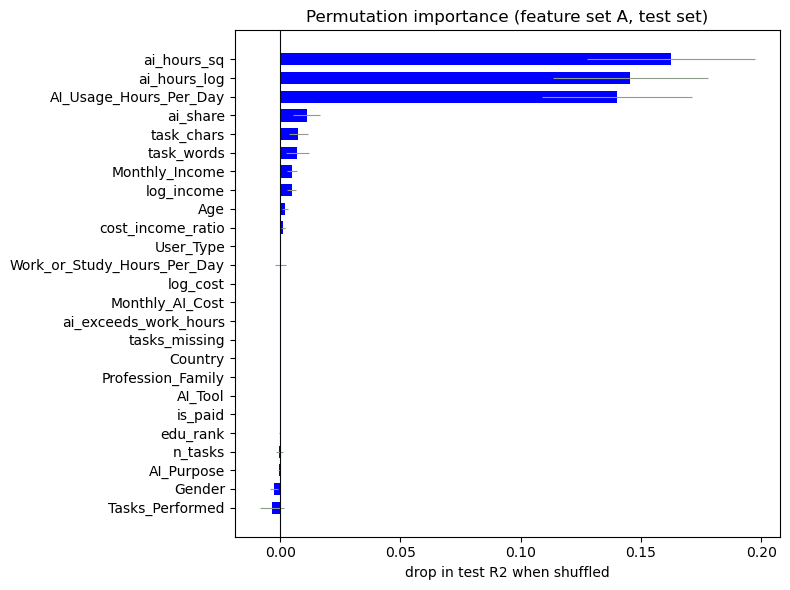

,feature,importance,std
5,ai_hours_sq,0.163,0.035
4,ai_hours_log,0.146,0.032
3,AI_Usage_Hours_Per_Day,0.140,0.031
7,ai_share,0.011,0.006
16,task_chars,0.007,0.004
15,task_words,0.007,0.005
1,Monthly_Income,0.005,0.002
2,log_income,0.005,0.002


In [45]:
# Permutation importance on the HOLD-OUT set (model-agnostic; drop in R2 when a column is shuffled)
pi = permutation_importance(final_A, X_test[feat_A], y_test, n_repeats=40, random_state=SEED, scoring="r2", n_jobs=-1)
imp = pd.DataFrame({"feature": feat_A, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp["feature"], imp["importance"], xerr=imp["std"], color=BLUE, height=0.65, error_kw=dict(lw=0.8, ecolor=MUTED))
ax.axvline(0, color=INK, lw=0.8); ax.set_xlabel("drop in test R2 when shuffled"); ax.set_title("Permutation importance (feature set A, test set)")
plt.tight_layout(); plt.show()
display(imp.sort_values("importance", ascending=False).head(8).round(4))

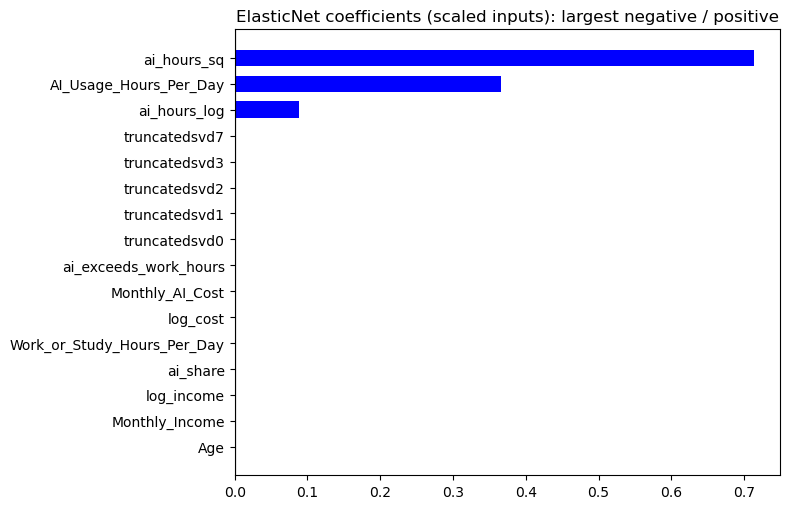

In [46]:
# Direction of effect: coefficients of the best linear model on the same features (interpretable companion)
lin_name = BEST_NAME if BEST_NAME in ("Ridge", "ElasticNet") else "ElasticNet"
ridge_pipe = tuned[lin_name].best_estimator_
pre_f = ridge_pipe.named_steps["pre"]; rm = ridge_pipe.named_steps["m"]
names = pre_f.get_feature_names_out()
coef = pd.Series(rm.coef_, index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.index, top.values, color=[ORANGE if v < 0 else BLUE for v in top.values], height=0.65)
ax.axvline(0, color=INK, lw=0.8); ax.set_title(f"{lin_name} coefficients (scaled inputs): largest negative / positive")
plt.tight_layout(); plt.show()

## 18. Secondary Task: Will the User Recommend AI? (Classification)

Target: `Would_Recommend == "Yes"` (vs "Maybe"/"No"). Here the perceived-outcome columns **are legitimate predictors**: a recommendation is a *downstream attitude* that follows from experienced satisfaction/productivity, so they are not leakage for this question (the target, `Would_Recommend`, is excluded and nothing derived from it is used).

Metrics: ROC-AUC (threshold-free), F1 and balanced accuracy (robust to class imbalance).

In [47]:
clf_df = fe.dropna(subset=["Would_Recommend"]).copy()
clf_df["y"] = (clf_df["Would_Recommend"] == "Yes").astype(int)
print("Class balance (Yes=1):", clf_df["y"].value_counts(normalize=True).round(3).to_dict())

num_clf = num_context + num_outcome + [TARGET]
feat_clf = num_clf + cat_cols + [TEXT_COL]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(clf_df[feat_clf], clf_df["y"], test_size=0.2, random_state=SEED, stratify=clf_df["y"])

clf_models = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Logistic (C=0.3)": LogisticRegression(C=0.3, max_iter=5000, class_weight="balanced"),
    "Logistic (C=0.03, strong L2)": LogisticRegression(C=0.03, max_iter=5000, class_weight="balanced"),
    "Random Forest (deep)": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features=0.4, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Random Forest (regularised)": RandomForestClassifier(n_estimators=300, min_samples_leaf=8, max_depth=4, max_features=0.4, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting (shallow)": GradientBoostingClassifier(n_estimators=100, learning_rate=0.03, max_depth=1, subsample=0.8, random_state=SEED),
}
cvc = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for n, m in clf_models.items():
    p = Pipeline([("pre", make_preprocessor(num_clf, scaler=BEST_SCALER)), ("m", m)])
    r = cross_validate(p, Xc_tr, yc_tr, cv=cvc, scoring=["roc_auc", "f1", "balanced_accuracy"], return_train_score=True, n_jobs=-1)
    rows.append({"model": n, "CV_AUC": r["test_roc_auc"].mean(), "Train_AUC": r["train_roc_auc"].mean(),
                 "CV_F1": r["test_f1"].mean(), "CV_BalAcc": r["test_balanced_accuracy"].mean()})
clf_res = pd.DataFrame(rows).set_index("model"); clf_res["AUC gap"] = clf_res["Train_AUC"] - clf_res["CV_AUC"]
display(clf_res.round(3))
print("Note: bagged trees always show a very high TRAIN AUC (they memorise in-bag rows); the honest signals are the CV AUC and the test AUC.")

Class balance (Yes=1): {1: 0.61, 0: 0.39}


,CV_AUC,Train_AUC,CV_F1,CV_BalAcc,AUC gap
model,,,,,
Dummy (prior),0.500,0.500,0.757,0.500,0.000
Logistic (C=0.3),0.706,0.914,0.696,0.631,0.208
"Logistic (C=0.03, strong L2)",0.733,0.868,0.706,0.652,0.134
Random Forest (deep),0.753,0.997,0.719,0.671,0.244
Random Forest (regularised),0.762,0.957,0.722,0.715,0.195
Gradient Boosting (shallow),0.777,0.901,0.733,0.668,0.124


Note: bagged trees always show a very high TRAIN AUC (they memorise in-bag rows); the honest signals are the CV AUC and the test AUC.


Best classifier: Gradient Boosting (shallow)
TEST  AUC=0.847 (95% CI 0.74-0.95)  F1=0.825  BalAcc=0.799  Acc=0.796


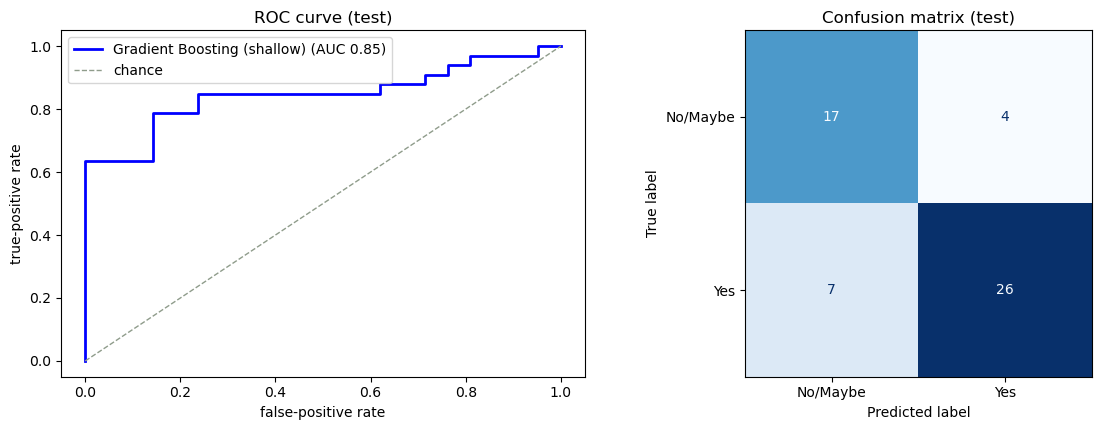

,drop in test AUC when shuffled
Satisfaction_Score,0.243
ai_share,0.037
task_chars,0.017
time_saved_per_ai_hour,0.005
Age,0.003
Work_or_Study_Hours_Per_Day,0.000
Productivity_Score,0.000
ai_hours_log,0.000


In [48]:
best_clf_name = clf_res.drop("Dummy (prior)")["CV_AUC"].idxmax()
clf_final = Pipeline([("pre", make_preprocessor(num_clf, scaler=BEST_SCALER)), ("m", clone(clf_models[best_clf_name]))]).fit(Xc_tr, yc_tr)
proba = clf_final.predict_proba(Xc_te)[:, 1]; pred_c = (proba >= 0.5).astype(int)
print(f"Best classifier: {best_clf_name}")
rng_c = np.random.default_rng(SEED); yv = yc_te.values; aucs = []
for _ in range(1000):
    i = rng_c.integers(0, len(yv), len(yv))
    if len(set(yv[i])) == 2: aucs.append(roc_auc_score(yv[i], proba[i]))
auc_ci = np.percentile(aucs, [2.5, 97.5])
print(f"TEST  AUC={roc_auc_score(yc_te, proba):.3f} (95% CI {auc_ci[0]:.2f}-{auc_ci[1]:.2f})  F1={f1_score(yc_te, pred_c):.3f}  "
      f"BalAcc={balanced_accuracy_score(yc_te, pred_c):.3f}  Acc={accuracy_score(yc_te, pred_c):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
fpr, tpr, _ = roc_curve(yc_te, proba)
ax[0].plot(fpr, tpr, color=BLUE, lw=2, label=f"{best_clf_name} (AUC {roc_auc_score(yc_te, proba):.2f})")
ax[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="chance"); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("true-positive rate")
ax[0].set_title("ROC curve (test)"); ax[0].legend()
ConfusionMatrixDisplay(confusion_matrix(yc_te, pred_c), display_labels=["No/Maybe", "Yes"]).plot(ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("Confusion matrix (test)"); ax[1].grid(False)
plt.tight_layout(); plt.show()

pic = permutation_importance(clf_final, Xc_te, yc_te, n_repeats=30, random_state=SEED, scoring="roc_auc", n_jobs=-1)
ic = pd.Series(pic.importances_mean, index=feat_clf).sort_values(ascending=False).head(8)
display(ic.round(4).to_frame("drop in test AUC when shuffled"))

## 19. Recommendations & Solution Summary

In [49]:
# Numbers below are pulled live from the results above so the text always matches the run.
a = report(y_test, pred_A); b = report(y_test, pred_B); d = report(y_test, pred_dummy)
ci = boot_ci(y_test, pred_A, r2_score)
top_feats = imp.sort_values("importance", ascending=False).head(4)["feature"].tolist()
display(Markdown(f"""
**Primary model (regression, leak-free feature set A):** tuned **{BEST_NAME}**

| | Dummy | Model A (deployable) | Model B (+outcome columns, NOT deployable) |
|---|---|---|---|
| Test R² | {d['R2']:.3f} | **{a['R2']:.3f}** (95% CI {ci[0]:.2f} to {ci[1]:.2f}) | {b['R2']:.3f} |
| Test RMSE | {d['RMSE']:.3f} | **{a['RMSE']:.3f}** | {b['RMSE']:.3f} |
| Test MAE | {d['MAE']:.3f} | **{a['MAE']:.3f}** | {b['MAE']:.3f} |

* Train–CV R² gap: **{gap:.3f}**; permutation test p = **{pval:.3f}**.
* Most important features (set A, permutation importance): **{', '.join(top_feats)}**.
* Classification ({best_clf_name}): test AUC **{roc_auc_score(yc_te, proba):.3f}**, balanced accuracy **{balanced_accuracy_score(yc_te, pred_c):.3f}**.
"""))


**Primary model (regression, leak-free feature set A):** tuned **Random Forest**

| | Dummy | Model A (deployable) | Model B (+outcome columns, NOT deployable) |
|---|---|---|---|
| Test R² | -0.116 | **0.601** (95% CI 0.42 to 0.74) | 0.625 |
| Test RMSE | 2.222 | **1.328** | 1.288 |
| Test MAE | 1.777 | **1.013** | 0.990 |

* Train–CV R² gap: **0.125**; permutation test p = **0.010**.
* Most important features (set A, permutation importance): **ai_hours_sq, ai_hours_log, AI_Usage_Hours_Per_Day, ai_share**.
* Classification (Gradient Boosting (shallow)): test AUC **0.847**, balanced accuracy **0.799**.


### 19.1 Solution summary

| Stage | What was done | Outcome |
|---|---|---|
| Cleaning | Parsed units (`hrs`, `$`, `yrs`), harmonised gender / country / education / tool labels, mapped 126 free-text professions to 7 role families, applied plausibility rules, removed duplicates | 300 → **274 usable rows** (12 duplicate respondents and 14 rows with no target removed); 6 impossible values blanked (age 97 ×2, income 250,000, 23 AI-hrs/day, 20 work-hrs ×2) |
| EDA | Distributions, correlations (Pearson & Spearman), Mann-Whitney / Kruskal-Wallis / Spearman with Benjamini-Hochberg FDR correction | Only **AI usage hours, time saved and satisfaction** are significantly related to productivity |
| Feature engineering | log(1+x), squares, AI-share of working time, cost/income ratio, task-text statistics, TF-IDF→SVD topics | 84 encoded model inputs; log transform cut income skew from ≈15.8 to ≈-1.1 |
| Scaling | Compared none / standard / robust / Yeo-Johnson (CV) | **Yeo-Johnson** gave the lowest average CV error for linear / KNN / SVR models |
| Reduction | Variance filter, correlation, VIF, PCA (manual eigen-decomposition verified), L1 | Reduction did **not** improve the best (tree) models; regularised models handle the collinearity themselves |
| Modelling | 11 regressors, repeated 5×3 CV, tuning, nested CV | Tuned **Random Forest**: nested-CV R² ≈ 0.60, ≈ 37 % lower RMSE than the baseline |
| Hold-out test | Scored once on 55 untouched rows | R² ≈ 0.60 (95 % bootstrap CI ≈ 0.42–0.74), MAE ≈ 1.0 point on a 10-point scale |
| Classification | Would the user recommend AI? | Shallow gradient boosting: test AUC ≈ 0.82 (95 % CI ≈ 0.69–0.94) |

### 19.2 Is the model trustworthy? (under-fit / over-fit / leakage verdict)

* **Not under-fitted:** it beats the mean-predictor baseline by roughly 37 % in RMSE, and the learning curve flattens, so more model complexity would not help.
* **Not materially over-fitted:** the tuned model's train-to-CV R² gap is ≈ 0.12, and CV (≈ 0.59) and test (≈ 0.60) R² agree. The deliberately unconstrained forests in §12 show gaps of 0.3–0.4 (typical for bagged trees on 200 rows), which is why tuning pushed towards shallow, heavily regularised trees.
* **No leakage found:** the split precedes every fitted step, all fitted steps live inside pipelines, no train/test overlap, the target-shuffle test gives R² ≈ -0.08 (p ≈ 0.01 for the real score), and no feature is suspiciously perfect.
* **Target-adjacent columns:** adding the perceived-outcome columns (accuracy, satisfaction, time saved) lifts CV RMSE by only 6-14 % and test R² from ≈ 0.60 to ≈ 0.63. They were left out of the deployable model because they are measured at the same moment as the target and would not be available when predicting.
* **Caveat on the test score:** the 55-row test set is more spread out than the training data (the baseline RMSE is 2.2 on test vs 1.7 in CV) and has a higher mean target, so absolute test RMSE (≈ 1.3) looks worse than CV RMSE (≈ 1.1) even though R² matches. The confidence interval is wide for the same reason.

### 19.3 Recommendations

1. **Drive engagement, not tool choice.** Daily AI hours is by far the strongest correlate of productivity (ρ ≈ 0.81). Tool, purpose, profession family, education, country, gender, age, income and student/professional status show **no significant differences** after FDR correction. Organisations should invest in onboarding, training and habit-building so people use AI regularly and meaningfully, rather than debating which brand to buy.
2. **Don't pay for premium tiers on productivity grounds alone.** Monthly AI cost has no meaningful relationship with productivity (ρ ≈ -0.07, not significant). Start with free or the cheapest adequate tier and measure usage.
3. **Don't use "perceived accuracy" as a success KPI.** It is essentially unrelated to productivity (ρ ≈ 0.07). Track usage time, time saved and satisfaction instead.
4. **Use the model as a coarse screening tool.** With an average error of about 1 point on a 10-point scale, it is suited to flagging low-benefit users for coaching (e.g. light or sporadic users), not to ranking individuals precisely.
5. **To grow advocacy, improve satisfaction.** For "would you recommend", satisfaction is the dominant predictor (shuffling it drops test AUC by ≈ 0.25), far ahead of everything else. UX, support and reliability work should pay off in word-of-mouth adoption.
6. **Be careful with heavy use.** Very high daily hours are rare in the data (few points above 8 h), so conclusions there are uncertain, and the survey has no wellbeing or quality-of-output measures. Don't conclude that "more is always better".
7. **Improve data collection.** Use dropdowns and validated numeric fields (units, ranges), unique respondent IDs, standard country / education / tool lists, and consider objective measures (task completion time, grades, output quality).
8. **Establish causality before big decisions.** This is a self-reported cross-sectional survey: heavy users may be more productive *because of* AI, or already-productive people may simply use AI more. A pilot with before/after or randomised comparison would settle this.

### 19.4 Limitations and next steps

* Small sample (274 rows), so results have wide uncertainty; repeat with more data and report intervals.
* Self-reported outcomes (productivity, satisfaction, time saved) are subject to response bias and are strongly correlated with each other.
* Next steps: collect more data, try monotonic-constrained boosting for the usage-hours effect, add SHAP explanations, calibrate the classifier probabilities, and monitor drift if the model is deployed.